# Formula 1 Podium Prediction Companion — Milestone 1

**Task:** predict whether a driver finishes on the podium (`positionOrder <= 3`) using only information available **after qualifying and before the race starts**.

**Unit of analysis:** one driver entering one race, i.e. one row per `(raceId, driverId)`.

## Notebook map
| Section | Content |
|---|---|
| 0 | Setup, data loading, coverage check |
| 1 | EDA **before** cleaning (sentinels, raw text types, missingness by era) |
| 2 | Cleaning: sentinel handling and semantic typing (on copies; raw stays immutable) |
| 3 | Primary-key and foreign-key audit |
| 4 | Grain fix: one row per `(raceId, driverId)`, duplicate rule and sensitivity test |
| 5 | EDA **after** cleaning (impact of cleaning, target, qualifying-coverage drift) |
| 6 | Cleaning summary (before vs after) |
| 7 | Data-engineering questions 1-3 with plots |
| 8 | Leakage-safe feature engineering, leakage tests, chronological split, feature evidence |
| 9 | Models (baseline, gradient boosting, random forest, shallow NN), metrics, comparison |
| 10 | Experiments: feature build-up, ablation, preprocessing order, training window |
| 11 | Explainability: permutation importance, SHAP, local SHAP, LIME |
| 12 | Inference function (complete and partially missing record) |
| 13 | Results summary and limitations |

Sections 7 onward build on the `base` table created in Section 4.

## 0. Setup and data loading
The data folder is auto-detected (Kaggle mounts datasets under different paths depending on the notebook version), so no path needs editing by hand.

In [116]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
SEED = 42

hits = glob.glob("/kaggle/input/**/results.csv", recursive=True)
assert hits, "results.csv not found - attach the F1 dataset with Add Input"
DATA_DIR = os.path.dirname(hits[0])
print("DATA_DIR =", DATA_DIR)

TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings",
          "drivers", "driver_standings", "races", "results", "qualifying",
          "lap_times", "pit_stops", "sprint_results", "seasons", "status"]
missing_files = [t for t in TABLES if not os.path.exists(f"{DATA_DIR}/{t}.csv")]
assert not missing_files, f"Missing tables: {missing_files}"

DATA_DIR = /kaggle/input/datasets/joesamy/formula-1-world-championship-1950-2020


In [117]:
# RAW = immutable snapshot of the CSVs, read as plain text so nothing is silently converted.
# Cleaning in Section 2 happens on copies (CLEAN); RAW is never modified.
RAW = {t: pd.read_csv(f"{DATA_DIR}/{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}

overview = pd.DataFrame({t: {"rows": len(df), "columns": df.shape[1]} for t, df in RAW.items()}).T
display(overview)

season_years = pd.to_numeric(RAW["races"]["year"])
print(f"Seasons covered: {season_years.min()} to {season_years.max()}")
if season_years.max() < 2024:
    print("WARNING: this copy of the dataset ends before 2024. Question 3 asks about 2022-2024, "
          "so the data must be extended or the limitation documented in the report.")

,rows,columns
circuits,77,9
constructors,212,5
constructor_results,12625,5
constructor_standings,13391,7
drivers,861,9
driver_standings,34863,7
races,1125,18
results,26759,18
qualifying,10494,9
lap_times,589081,6


Seasons covered: 1950 to 2024


## 1. EDA before cleaning
Goal: measure what is wrong with the raw data *before* touching it, so Section 5 can show the effect of cleaning.

Findings to look for:
1. The CSVs use the literal string `\N` as a missing-value marker (a "sentinel"), so pandas does not see these as missing.
2. Every column is text on load: dates, lap times and numbers all need typing.
3. Missingness is not random: it depends on the era (e.g. no qualifying times in the early years).

30 of 120 columns contain the \N sentinel; 160,076 sentinel cells in total.


,table,column,n_rows,n_sentinel,n_empty,pct_sentinel
18,constructor_results,status,12625,12608,0,99.865347
59,races,sprint_time,1125,1110,0,98.666667
58,races,sprint_date,1125,1107,0,98.400000
55,races,fp3_time,1125,1072,0,95.288889
53,races,fp2_time,1125,1057,0,93.955556
51,races,fp1_time,1125,1057,0,93.955556
57,races,quali_time,1125,1057,0,93.955556
54,races,fp3_date,1125,1053,0,93.600000
28,drivers,number,861,802,0,93.147503
50,races,fp1_date,1125,1035,0,92.000000


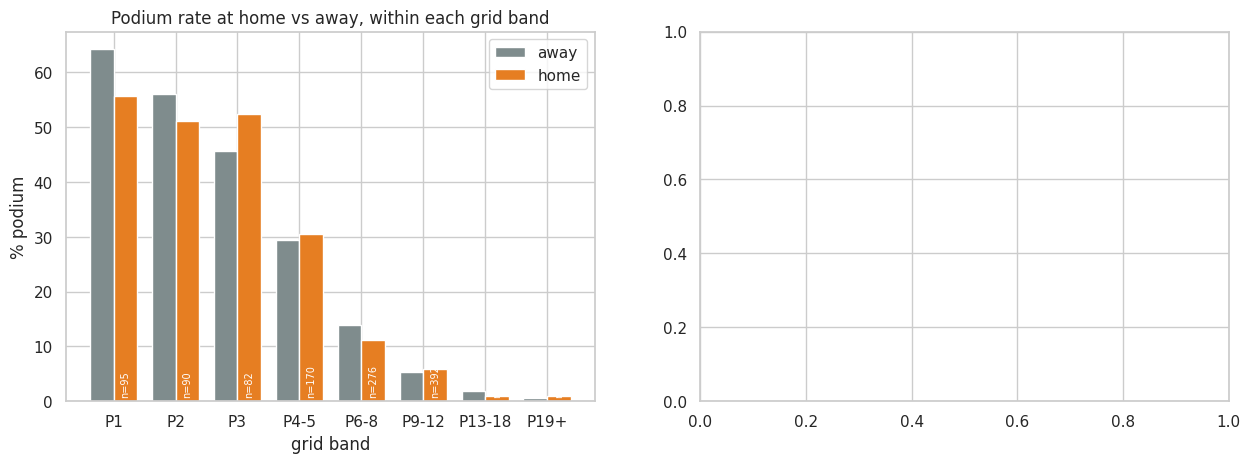

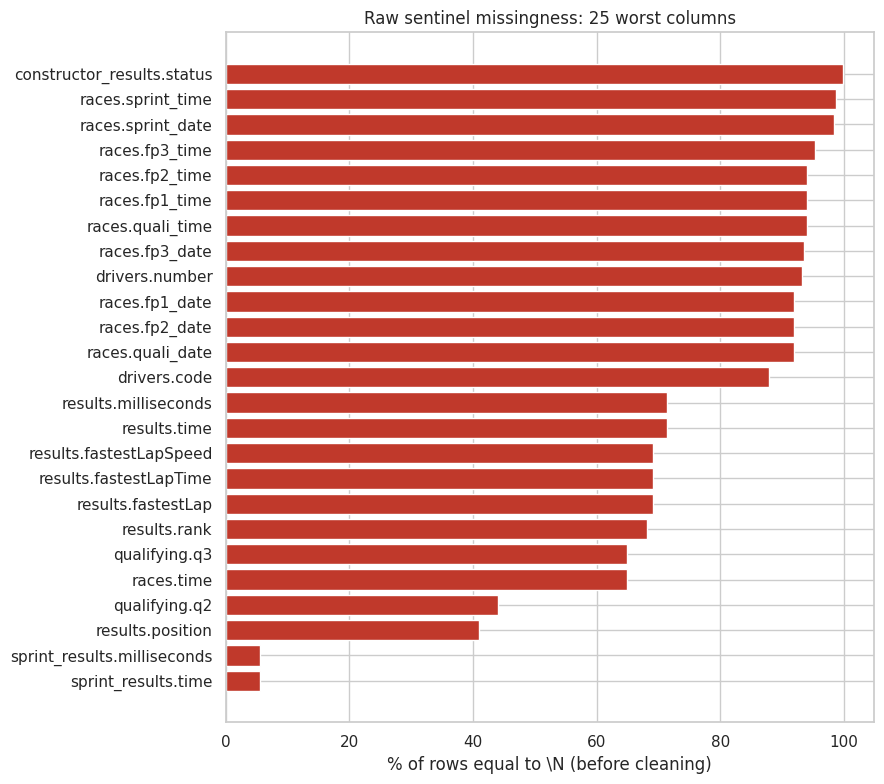

In [118]:
SENT = "\\N"   # the literal two-character string backslash-N used by the dataset

rows = []
for t, df in RAW.items():
    for c in df.columns:
        rows.append((t, c, len(df), int((df[c] == SENT).sum()), int((df[c] == "").sum())))
audit_before = pd.DataFrame(rows, columns=["table", "column", "n_rows", "n_sentinel", "n_empty"])
audit_before["pct_sentinel"] = 100 * audit_before["n_sentinel"] / audit_before["n_rows"]

has_sent = audit_before[audit_before["n_sentinel"] > 0].sort_values("pct_sentinel", ascending=False)
print(f"{len(has_sent)} of {len(audit_before)} columns contain the \\N sentinel; "
      f"{audit_before['n_sentinel'].sum():,} sentinel cells in total.")
display(has_sent.head(30))

top = has_sent.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top["table"] + "." + top["column"], top["pct_sentinel"], color="#c0392b")
ax.set_xlabel("% of rows equal to \\N (before cleaning)")
ax.set_title("Raw sentinel missingness: 25 worst columns")
plt.tight_layout(); plt.show()

In [119]:
# What the raw text actually looks like: everything is a string, times are "m:ss.mmm", missing is "\N".
print("Raw results (note \\N and mixed text):")
display(RAW["results"][["position", "positionText", "fastestLapTime", "time", "milliseconds"]].sample(8, random_state=SEED))
print("Raw qualifying times:")
display(RAW["qualifying"][["q1", "q2", "q3"]].sample(8, random_state=SEED))
print("Raw race dates and times:")
display(RAW["races"][["year", "date", "time", "fp1_date"]].sample(8, random_state=SEED))
print("dtypes in RAW:", {str(d) for df in RAW.values() for d in df.dtypes})

Raw results (note \N and mixed text):


,position,positionText,fastestLapTime,time,milliseconds
3482,4,4,\N,+52.803,5345241
4202,\N,R,\N,\N,\N
10980,\N,R,\N,\N,\N
19917,1,1,\N,3:22:11.0,12131000
19682,\N,R,\N,\N,\N
2904,\N,R,\N,\N,\N
10880,2,2,\N,+19.161,5098941
14568,\N,R,\N,\N,\N


Raw qualifying times:


,q1,q2,q3
6792,1:14.121,1:13.076,1:12.812
8563,1:27.378,1:26.361,1:26.709
6429,1:12.001,1:09.652,1:09.713
7028,1:33.353,\N,\N
10406,1:17.307,1:17.168,\N
8358,1:04.661,1:03.746,1:03.868
3328,1:55.463,1:54.682,1:55.241
4907,1:27.479,1:27.247,\N


Raw race dates and times:


,year,date,time,fp1_date
1089,2023,2023-07-23,13:00:00,2023-07-21
1103,2024,2024-03-24,04:00:00,2024-03-22
739,1961,1961-06-18,\N,\N
140,2001,2001-03-04,\N,\N
1018,2020,2020-07-05,13:10:00,\N
527,1978,1978-01-29,\N,\N
812,1953,1953-07-18,\N,\N
481,1982,1982-09-25,\N,\N


dtypes in RAW: {'object'}


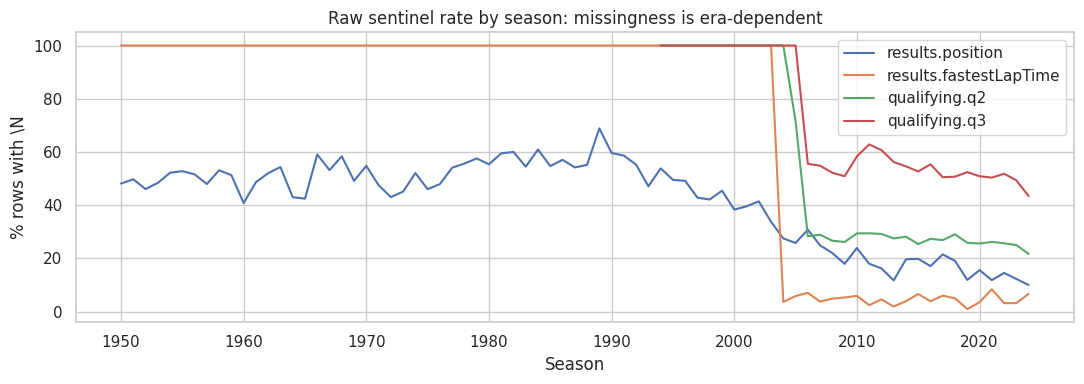

In [120]:
# Missingness depends on the era -> it is informative, not random noise.
race_year = pd.to_numeric(RAW["races"].set_index("raceId")["year"])

def sentinel_rate_by_year(table, col):
    df = RAW[table]
    yr = df["raceId"].map(race_year)
    return (df[col] == SENT).groupby(yr).mean() * 100

fig, ax = plt.subplots(figsize=(11, 4))
for table, col in [("results", "position"), ("results", "fastestLapTime"), ("qualifying", "q2"), ("qualifying", "q3")]:
    s = sentinel_rate_by_year(table, col)
    ax.plot(s.index, s.values, label=f"{table}.{col}")
ax.set_xlabel("Season"); ax.set_ylabel("% rows with \\N")
ax.set_title("Raw sentinel rate by season: missingness is era-dependent")
ax.legend(); plt.tight_layout(); plt.show()

## 2. Cleaning: sentinels and semantic typing
Implementation choices (all applied to **copies**; `RAW` is untouched):

- **Sentinels:** replace `\N` (and empty strings) with real `NaN`. Missing means "the value does not exist" (e.g. a driver who did not set a Q3 time), not zero, so we do not impute at this stage.
- **Numbers:** convert a column to numeric only if *every* non-missing value parses; otherwise it stays text. This avoids silently destroying mixed columns such as `positionText` (contains `R`, `D`, `W`).
- **Dates:** `races.date`, practice/quali/sprint dates and `drivers.dob` become `datetime64`.
- **Durations:** lap-time strings like `1:27.452` become numeric **seconds** (`results.fastestLapTime`, `qualifying.q1-q3`, `lap_times.time`, `pit_stops.duration`).

In [121]:
DATE_COLS = {
    "races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
    "drivers": ["dob"],
}
DURATION_COLS = {
    "results": ["fastestLapTime"],
    "sprint_results": ["fastestLapTime"],
    "qualifying": ["q1", "q2", "q3"],
    "lap_times": ["time"],
    "pit_stops": ["duration"],
}

def to_seconds(s):
    """'1:27.452' -> 87.452 ; '23.456' -> 23.456 ; missing/invalid -> NaN."""
    if pd.isna(s):
        return np.nan
    s = str(s).strip()
    try:
        if ":" in s:
            m, r = s.split(":", 1)
            return int(m) * 60 + float(r)
        return float(s)
    except ValueError:
        return np.nan

def clean_table(df, table):
    out = df.replace({SENT: np.nan, "": np.nan})       # 1) sentinels -> NaN (returns a copy)
    for c in out.columns:
        if c in DATE_COLS.get(table, []):               # 2) dates
            out[c] = pd.to_datetime(out[c], errors="coerce")
        elif c in DURATION_COLS.get(table, []):         # 3) durations -> seconds
            out[c] = out[c].map(to_seconds).astype(float)
        else:                                           # 4) numeric only if nothing is lost
            conv = pd.to_numeric(out[c], errors="coerce")
            if conv.notna().sum() == out[c].notna().sum():
                out[c] = conv
    return out

CLEAN = {t: clean_table(df, t) for t, df in RAW.items()}
assert all((RAW[t].dtypes == object).all() for t in TABLES), "RAW must remain untouched text"

def dtype_summary(frames):
    rows = []
    for t, df in frames.items():
        kind = df.dtypes.map(lambda d: "datetime" if "datetime" in str(d)
                             else ("numeric" if pd.api.types.is_numeric_dtype(d) else "text"))
        rows.append({"table": t, **kind.value_counts().to_dict()})
    return pd.DataFrame(rows).fillna(0).set_index("table").astype(int)

dt_before, dt_after = dtype_summary(RAW), dtype_summary(CLEAN)
print("Column types BEFORE cleaning:"); display(dt_before)
print("Column types AFTER cleaning:"); display(dt_after)

Column types BEFORE cleaning:


,text
table,
circuits,9
constructors,5
constructor_results,5
constructor_standings,7
drivers,9
driver_standings,7
races,18
results,18
qualifying,9


Column types AFTER cleaning:


,text,numeric,datetime
table,,,
circuits,5,4,0
constructors,4,1,0
constructor_results,1,4,0
constructor_standings,1,6,0
drivers,6,2,1
driver_standings,1,6,0
races,8,4,6
results,2,16,0
qualifying,0,9,0


Sentinel cells remaining after cleaning: 0


,q1_raw,q1_seconds
6779,1:15.504,75.504
6204,1:35.308,95.308
770,1:34.667,94.667
10469,1:22.390,82.390
566,1:31.522,91.522
9638,1:42.197,102.197


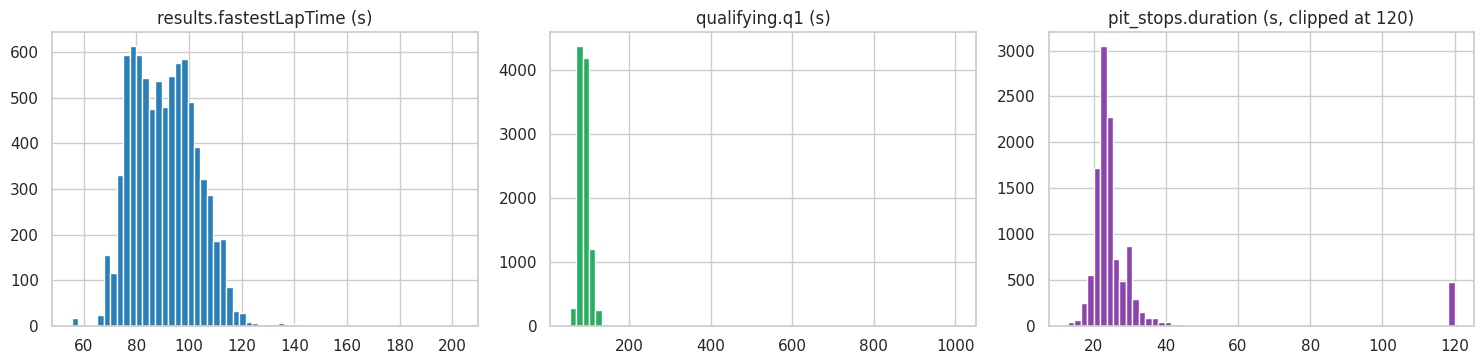

Date columns now typed: datetime64[ns] | races range: 1950-05-13 to 2024-12-08


In [122]:
# Verify no sentinel survived and that conversions behaved.
leftover = 0
for t, df in CLEAN.items():
    for c in df.select_dtypes("object").columns:
        leftover += int((df[c] == SENT).sum())
print("Sentinel cells remaining after cleaning:", leftover)
assert leftover == 0

# Example of the conversion: raw string vs numeric seconds
ex = RAW["qualifying"][["q1"]].rename(columns={"q1": "q1_raw"}).join(CLEAN["qualifying"][["q1"]].rename(columns={"q1": "q1_seconds"}))
display(ex.dropna().sample(6, random_state=SEED))

# Sanity of converted durations (outliers would reveal parsing problems)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
CLEAN["results"]["fastestLapTime"].dropna().hist(ax=axes[0], bins=60, color="#2980b9")
axes[0].set_title("results.fastestLapTime (s)")
CLEAN["qualifying"]["q1"].dropna().hist(ax=axes[1], bins=60, color="#27ae60")
axes[1].set_title("qualifying.q1 (s)")
CLEAN["pit_stops"]["duration"].dropna().clip(upper=120).hist(ax=axes[2], bins=60, color="#8e44ad")
axes[2].set_title("pit_stops.duration (s, clipped at 120)")
plt.tight_layout(); plt.show()

print("Date columns now typed:", CLEAN["races"]["date"].dtype, "| races range:",
      CLEAN["races"]["date"].min().date(), "to", CLEAN["races"]["date"].max().date())

## 3. Primary-key and foreign-key audit
- **Primary key (PK):** the column(s) that identify a row must be unique and non-null.
- **Foreign key (FK):** every value in a child column must exist in the parent table (no orphans).

Tables such as `lap_times` and `pit_stops` have composite keys. Note that `results` has its own PK (`resultId`), but the **modeling grain** `(raceId, driverId)` is a different, stricter key that we enforce in Section 4.

In [123]:
PK = {
    "circuits": ["circuitId"], "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"], "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"], "driver_standings": ["driverStandingsId"], "races": ["raceId"],
    "results": ["resultId"], "qualifying": ["qualifyId"], "seasons": ["year"], "status": ["statusId"],
    "sprint_results": ["resultId"], "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
}
pk_rows = []
for t, cols in PK.items():
    df = CLEAN[t]
    pk_rows.append({"table": t, "key": " + ".join(cols), "n_rows": len(df),
                    "null_keys": int(df[cols].isna().any(axis=1).sum()),
                    "duplicate_keys": int(df.duplicated(cols).sum())})
pk_report = pd.DataFrame(pk_rows)
pk_report["ok"] = (pk_report["null_keys"] == 0) & (pk_report["duplicate_keys"] == 0)
display(pk_report)
print("All primary keys valid:", bool(pk_report["ok"].all()))

,table,key,n_rows,null_keys,duplicate_keys,ok
0,circuits,circuitId,77,0,0,True
1,constructors,constructorId,212,0,0,True
2,constructor_results,constructorResultsId,12625,0,0,True
3,constructor_standings,constructorStandingsId,13391,0,0,True
4,drivers,driverId,861,0,0,True
5,driver_standings,driverStandingsId,34863,0,0,True
6,races,raceId,1125,0,0,True
7,results,resultId,26759,0,0,True
8,qualifying,qualifyId,10494,0,0,True
9,seasons,year,75,0,0,True


All primary keys valid: True


,fk,checked,null_fk,orphans
0,results.raceId -> races.raceId,26759,0,0
1,results.driverId -> drivers.driverId,26759,0,0
2,results.constructorId -> constructors.construc...,26759,0,0
3,results.statusId -> status.statusId,26759,0,0
4,races.circuitId -> circuits.circuitId,1125,0,0
5,races.year -> seasons.year,1125,0,0
6,qualifying.raceId -> races.raceId,10494,0,0
7,qualifying.driverId -> drivers.driverId,10494,0,0
8,qualifying.constructorId -> constructors.const...,10494,0,0
9,lap_times.raceId -> races.raceId,589081,0,0


Total orphan foreign-key values: 0


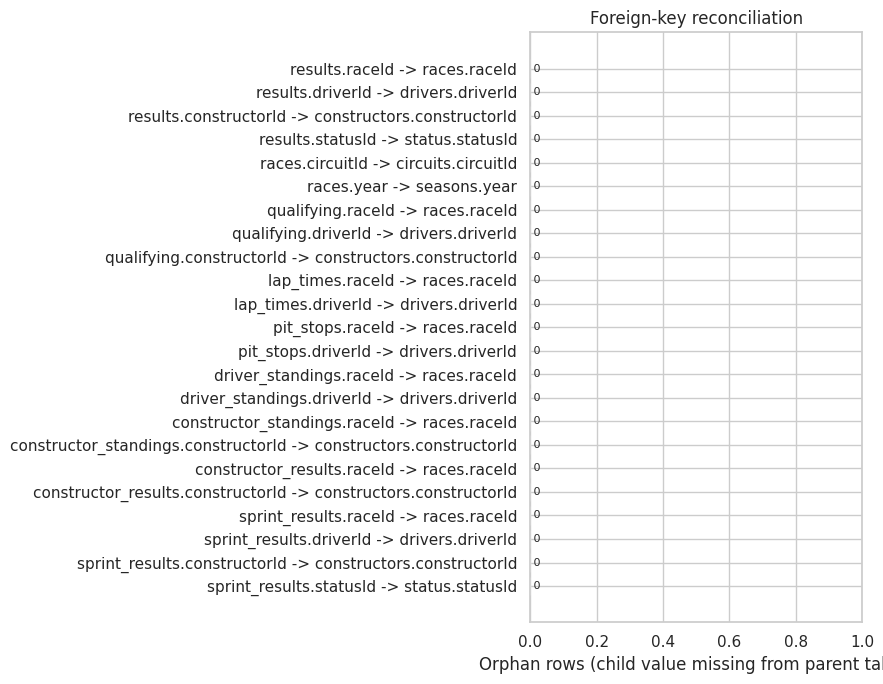

In [124]:
FK = [
    ("results", "raceId", "races", "raceId"), ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"), ("results", "statusId", "status", "statusId"),
    ("races", "circuitId", "circuits", "circuitId"), ("races", "year", "seasons", "year"),
    ("qualifying", "raceId", "races", "raceId"), ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"), ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"), ("pit_stops", "driverId", "drivers", "driverId"),
    ("driver_standings", "raceId", "races", "raceId"), ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "raceId", "races", "raceId"), ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
]
fk_rows = []
for child, col, parent, pcol in FK:
    vals = CLEAN[child][col].dropna()
    n_orph = int((~vals.isin(CLEAN[parent][pcol])).sum())
    fk_rows.append({"fk": f"{child}.{col} -> {parent}.{pcol}", "checked": len(vals),
                    "null_fk": int(CLEAN[child][col].isna().sum()), "orphans": n_orph})
fk_report = pd.DataFrame(fk_rows)
display(fk_report)
print("Total orphan foreign-key values:", int(fk_report["orphans"].sum()))

fig, ax = plt.subplots(figsize=(9, 7))
plot_df = fk_report.iloc[::-1]
ax.barh(plot_df["fk"], plot_df["orphans"], color="#e67e22")
for i, v in enumerate(plot_df["orphans"]):
    ax.text(v, i, f" {v}", va="center", fontsize=8)
ax.set_xlim(0, max(1, plot_df["orphans"].max() * 1.15))
ax.set_xlabel("Orphan rows (child value missing from parent table)")
ax.set_title("Foreign-key reconciliation")
plt.tight_layout(); plt.show()

**Reading the result:** if every `orphans` value is 0 and every PK is unique and non-null, the relational structure is sound and joins will not silently drop or invent rows. Any non-zero count would be listed here and handled explicitly (e.g. dropped from the modeling table with the count reported).

## 4. Grain: exactly one row per `(raceId, driverId)`
Each modeling row is one prediction ("will this driver finish on the podium in this race?"), so the pair must be unique. In early F1, drivers could share a car, so one driver can appear in more than one result row of the same race.

(raceId, driverId) pairs with more than one result row: 85
Rows involved: 176  |  extra rows to remove: 91
Years affected: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1960, 1961, 1962, 1964, 1978]


,resultId,year,race_name,surname,constructorId,grid,position,positionOrder,points,laps,statusId
0,13189,1978,Italian Grand Prix,Ertl,54,0,NaN,26,0.0,0,81
1,13192,1978,Italian Grand Prix,Ertl,57,0,NaN,29,0.0,0,97
2,17363,1964,United States Grand Prix,Clark,172,1,7.0,7,0.0,102,60
175,24304,1964,United States Grand Prix,Clark,172,1,NaN,12,0.0,54,98
3,17741,1962,British Grand Prix,Greene,172,0,NaN,22,0.0,0,54
4,17744,1962,British Grand Prix,Greene,97,0,NaN,25,0.0,0,54
5,17962,1961,British Grand Prix,Moss,102,20,NaN,19,0.0,56,2
6,17964,1961,British Grand Prix,Moss,172,5,NaN,21,0.0,44,23
7,18063,1961,United States Grand Prix,Gregory,172,11,NaN,17,0.0,23,6
174,24303,1961,United States Grand Prix,Gregory,172,15,11.0,11,0.0,92,18


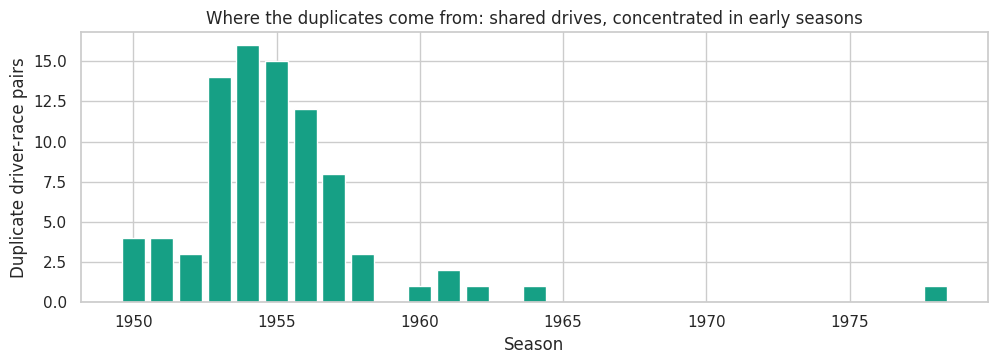

In [125]:
races = CLEAN["races"]; drivers = CLEAN["drivers"]; constructors = CLEAN["constructors"]
res = CLEAN["results"]

dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = (res[dup_mask]
        .merge(races[["raceId", "year", "round", "name"]].rename(columns={"name": "race_name"}), on="raceId", how="left")
        .merge(drivers[["driverId", "surname"]], on="driverId", how="left")
        .sort_values(["raceId", "driverId", "resultId"]))
n_groups = dups.drop_duplicates(["raceId", "driverId"]).shape[0]
n_extra = int(res.duplicated(["raceId", "driverId"]).sum())
print(f"(raceId, driverId) pairs with more than one result row: {n_groups}")
print(f"Rows involved: {len(dups)}  |  extra rows to remove: {n_extra}")

if len(dups):
    print("Years affected:", sorted(dups["year"].unique().astype(int).tolist()))
    display(dups[["resultId", "year", "race_name", "surname", "constructorId", "grid",
                  "position", "positionOrder", "points", "laps", "statusId"]].head(12))
    by_year = dups.drop_duplicates(["raceId", "driverId"]).groupby("year").size()
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.bar(by_year.index.astype(int), by_year.values, color="#16a085")
    ax.set_xlabel("Season"); ax.set_ylabel("Duplicate driver-race pairs")
    ax.set_title("Where the duplicates come from: shared drives, concentrated in early seasons")
    plt.tight_layout(); plt.show()

### Duplicate rule (a judgment call; be ready to defend it)
**Chosen rule: keep the row with the best (lowest non-zero) `grid` position; break ties with the lowest `resultId`.**

Why:
- The rule uses only information that exists **before the race** (grid), so the choice of row is not influenced by the outcome we are predicting.
- The obvious alternative, "keep the row with the best finishing position", selects rows **using the label**. That inflates the podium rate for shared-drive drivers and builds label-driven selection bias into the table.
- `resultId` is a deterministic tie-breaker, so the table is reproducible.

Because the rule is a choice, we also run a **sensitivity check**: how many podium labels would change under the alternative rule? If almost none, the choice barely matters.

In [126]:
def dedup(df, rule="grid"):
    d = df.copy()
    if rule == "grid":
        d["_grid_key"] = d["grid"].where(d["grid"] > 0, np.inf)   # grid 0 (pit lane) ranks last
        d = d.sort_values(["raceId", "driverId", "_grid_key", "resultId"])
    elif rule == "best_finish":
        d = d.sort_values(["raceId", "driverId", "positionOrder", "resultId"])
    else:
        raise ValueError(rule)
    d = d.drop_duplicates(["raceId", "driverId"], keep="first")
    return d.drop(columns=["_grid_key"], errors="ignore")

a, b = dedup(res, "grid"), dedup(res, "best_finish")
cmp = (a[["raceId", "driverId", "positionOrder"]]
       .merge(b[["raceId", "driverId", "positionOrder"]], on=["raceId", "driverId"], suffixes=("_grid", "_best")))
podium_a, podium_b = cmp["positionOrder_grid"] <= 3, cmp["positionOrder_best"] <= 3
sens = pd.DataFrame({
    "rule": ["grid-based (chosen)", "best-finish (alternative)"],
    "rows": [len(a), len(b)],
    "podium_rows": [int(podium_a.sum()), int(podium_b.sum())],
    "podium_rate_%": [round(100 * podium_a.mean(), 4), round(100 * podium_b.mean(), 4)],
})
display(sens)
print("Podium labels that differ between the two rules:", int((podium_a != podium_b).sum()),
      f"of {len(cmp):,} rows")

# Final unique driver-race table
results_unique = a.copy()
results_unique["podium"] = (results_unique["positionOrder"] <= 3).astype(int)
assert results_unique["positionOrder"].notna().all()
assert not results_unique.duplicated(["raceId", "driverId"]).any()
print(f"results rows: {len(res):,} -> unique driver-race rows: {len(results_unique):,}")

,rule,rows,podium_rows,podium_rate_%
0,grid-based (chosen),26668,3378,12.6669
1,best-finish (alternative),26668,3395,12.7306


Podium labels that differ between the two rules: 17 of 26,668 rows
results rows: 26,759 -> unique driver-race rows: 26,668


In [127]:
# Base modeling table: one row per driver per race, with descriptive context joined in (validate="m:1" guards the grain).
base = (results_unique
        .merge(races[["raceId", "year", "round", "circuitId", "date", "name"]].rename(columns={"name": "race_name"}),
               on="raceId", how="left", validate="m:1")
        .merge(drivers[["driverId", "driverRef", "surname", "nationality", "dob"]]
               .rename(columns={"nationality": "driver_nationality"}), on="driverId", how="left", validate="m:1")
        .merge(constructors[["constructorId", "name", "nationality"]]
               .rename(columns={"name": "constructor_name", "nationality": "constructor_nationality"}),
               on="constructorId", how="left", validate="m:1")
        .sort_values(["date", "raceId", "grid"]).reset_index(drop=True))

assert len(base) == len(results_unique)
assert not base.duplicated(["raceId", "driverId"]).any()
assert base["podium"].isin([0, 1]).all()
print("base shape:", base.shape)
print("Podium rate: {:.2%} ({} podium rows out of {:,})".format(base["podium"].mean(), base["podium"].sum(), len(base)))
display(base[["raceId", "year", "race_name", "surname", "constructor_name", "grid", "positionOrder", "podium"]].tail(5))

base shape: (26668, 30)
Podium rate: 12.67% (3378 podium rows out of 26,668)


,raceId,year,race_name,surname,constructor_name,grid,positionOrder,podium
26663,1144,2024,Abu Dhabi Grand Prix,Hamilton,Mercedes,16,4,0
26664,1144,2024,Abu Dhabi Grand Prix,Doohan,Alpine F1 Team,17,15,0
26665,1144,2024,Abu Dhabi Grand Prix,Albon,Williams,18,11,0
26666,1144,2024,Abu Dhabi Grand Prix,Leclerc,Ferrari,19,3,1
26667,1144,2024,Abu Dhabi Grand Prix,Colapinto,Williams,20,19,0


**Leakage note for later sections.** `base` still contains post-race columns from `results` (`position`, `positionOrder`, `points`, `laps`, `time`, `milliseconds`, `fastestLap*`, `statusId`). They exist only to build the label and the data-engineering answers. They are **dropped from the feature set** in the feature-engineering section; only `grid`, qualifying data and information from *earlier* races may be used as features.

## 5. EDA after cleaning
We now show the effect of cleaning on the data and look at the target and at qualifying coverage (needed later for feature choices and the limitations section).

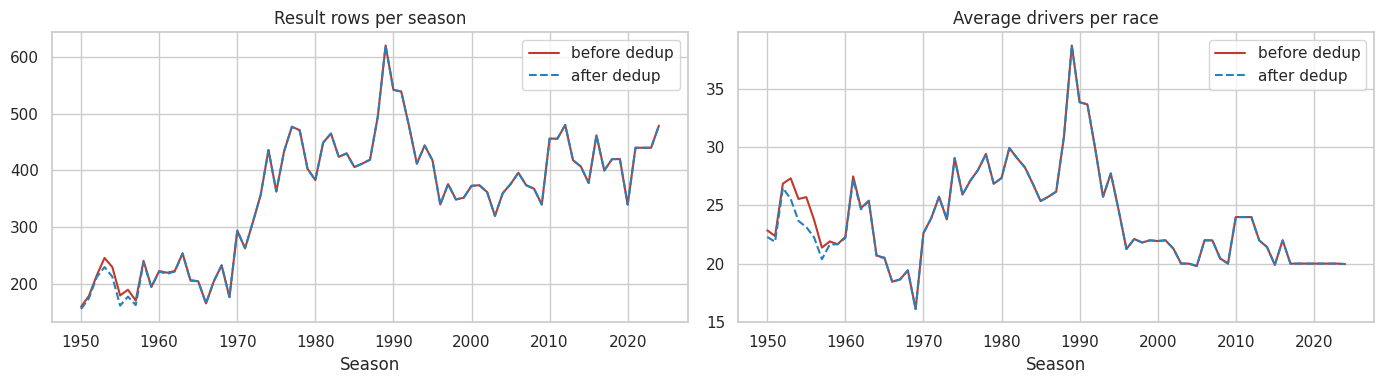

Rows removed by the grain fix: 91


In [128]:
# 5.1 Effect of deduplication on rows per season and field size
before = res.merge(races[["raceId", "year"]], on="raceId").groupby("year").size()
after = base.groupby("year").size()
field_before = res.merge(races[["raceId", "year"]], on="raceId").groupby("year").size() / races.groupby("year")["raceId"].nunique()
field_after = after / races.groupby("year")["raceId"].nunique()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(before.index, before.values, label="before dedup", color="#c0392b")
axes[0].plot(after.index, after.values, label="after dedup", color="#2980b9", linestyle="--")
axes[0].set_title("Result rows per season"); axes[0].set_xlabel("Season"); axes[0].legend()
axes[1].plot(field_before.index, field_before.values, label="before dedup", color="#c0392b")
axes[1].plot(field_after.index, field_after.values, label="after dedup", color="#2980b9", linestyle="--")
axes[1].set_title("Average drivers per race"); axes[1].set_xlabel("Season"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Rows removed by the grain fix: {len(res) - len(base)}")

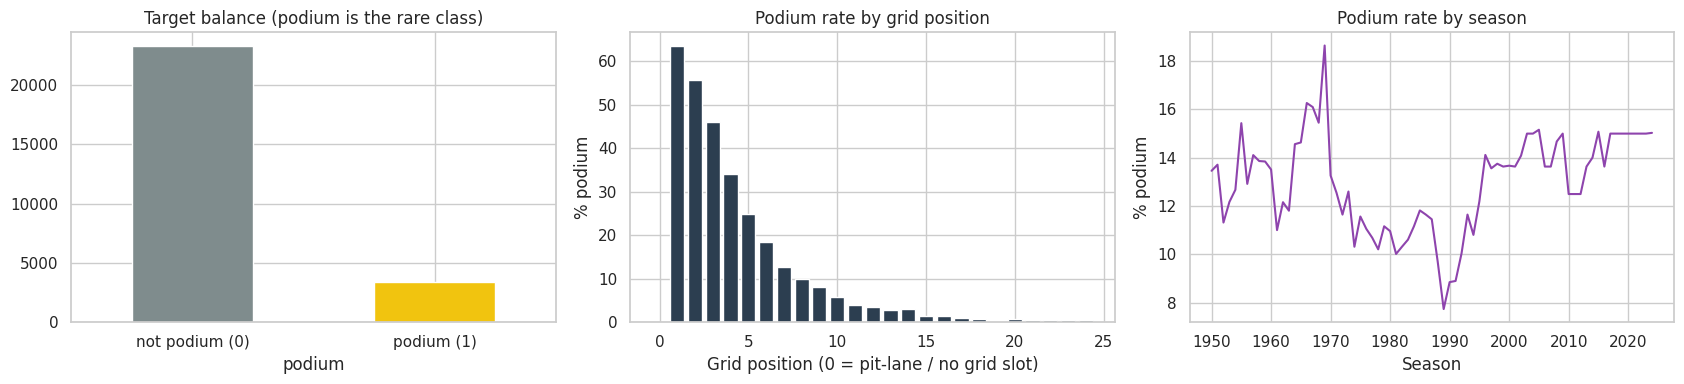

In [129]:
# 5.2 Target: class balance and the strongest pre-race signal (grid position)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

base["podium"].value_counts().sort_index().plot.bar(ax=axes[0], color=["#7f8c8d", "#f1c40f"])
axes[0].set_xticklabels(["not podium (0)", "podium (1)"], rotation=0)
axes[0].set_title("Target balance (podium is the rare class)")

g = base.groupby("grid")["podium"].agg(["mean", "size"]).reset_index()
g = g[(g["size"] >= 30) & (g["grid"] <= 24)]
axes[1].bar(g["grid"].astype(int), g["mean"] * 100, color="#2c3e50")
axes[1].set_xlabel("Grid position (0 = pit-lane / no grid slot)"); axes[1].set_ylabel("% podium")
axes[1].set_title("Podium rate by grid position")

by_year = base.groupby("year")["podium"].mean() * 100
axes[2].plot(by_year.index, by_year.values, color="#8e44ad")
axes[2].set_xlabel("Season"); axes[2].set_ylabel("% podium")
axes[2].set_title("Podium rate by season")
plt.tight_layout(); plt.show()

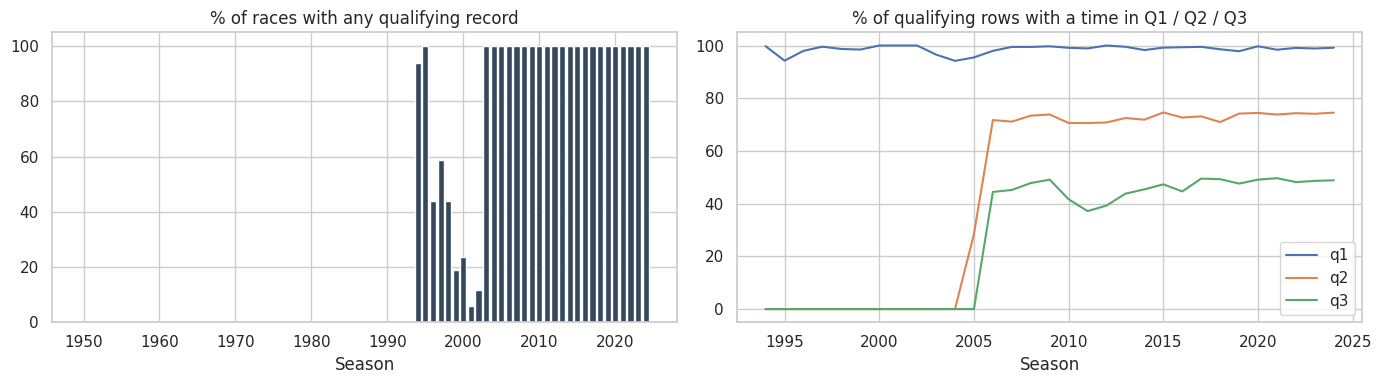

Qualifying records start in 1994. Before that, only grid position is available as a pre-race signal.


In [130]:
# 5.3 Qualifying coverage drift (limitation to carry into the report)
q = CLEAN["qualifying"].merge(races[["raceId", "year"]], on="raceId", how="left")
races_per_year = races.groupby("year")["raceId"].nunique()
cov = pd.DataFrame({"races": races_per_year,
                    "races_with_quali": q.groupby("year")["raceId"].nunique()}).fillna(0)
cov["pct_races_with_quali"] = 100 * cov["races_with_quali"] / cov["races"]
share = q.groupby("year")[["q1", "q2", "q3"]].apply(lambda d: d.notna().mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(cov.index, cov["pct_races_with_quali"], color="#34495e")
axes[0].set_title("% of races with any qualifying record"); axes[0].set_xlabel("Season")
for c in ["q1", "q2", "q3"]:
    axes[1].plot(share.index, share[c], label=c)
axes[1].set_title("% of qualifying rows with a time in Q1 / Q2 / Q3"); axes[1].set_xlabel("Season"); axes[1].legend()
plt.tight_layout(); plt.show()

first_q = int(cov[cov["races_with_quali"] > 0].index.min())
print(f"Qualifying records start in {first_q}. Before that, only grid position is available as a pre-race signal.")

## 6. Cleaning summary (before vs after)

In [131]:
summary = pd.DataFrame([
    ["Sentinel (\\N) cells", int(audit_before["n_sentinel"].sum()), leftover],
    ["Text columns (all tables)", int(dt_before["text"].sum()), int(dt_after["text"].sum())],
    ["Numeric columns", int(dt_before.get("numeric", pd.Series([0])).sum()), int(dt_after["numeric"].sum())],
    ["Datetime columns", int(dt_before.get("datetime", pd.Series([0])).sum()), int(dt_after["datetime"].sum())],
    ["Extra result rows sharing a (raceId, driverId)", n_extra, 0],
    ["Result rows", len(res), len(base)],
    ["Orphan foreign-key values", int(fk_report["orphans"].sum()), int(fk_report["orphans"].sum())],
], columns=["check", "before", "after"])
display(summary)

,check,before,after
0,Sentinel (\N) cells,160076,0
1,Text columns (all tables),120,33
2,Numeric columns,0,80
3,Datetime columns,0,7
4,"Extra result rows sharing a (raceId, driverId)",91,0
5,Result rows,26759,26668
6,Orphan foreign-key values,0,0


## 7. Data-engineering questions

**This section continues from Part 1** (it needs `CLEAN`, `base`, `races`, `drivers`, `constructors` already in memory), so run it in the same notebook, after Section 6.

For every question the write-up states three things the brief asks for:

| | Q1 front-row conversion | Q2 home advantage | Q3 mechanical retirements |
|---|---|---|---|
| **Grain** | one driver in one race (`base`), only races that have a qualifying record | one driver in one race (`base`), grid > 0 | one car start (one `base` row), 2014-2024 |
| **Tables joined** | `base` + `qualifying` + `circuits` | `base` + `drivers` nationality + `circuits` country | `base` + `status` + `constructors` |
| **Pre-race cutoff** | qualifying position and grid are pre-race; **podium is the outcome being studied, not a feature** | grid and home flag are pre-race; podium is the outcome | purely retrospective analysis of race outcomes (not a model feature) |

These three analyses describe *what happened*. They are not model features, so using race outcomes here is not leakage. Anything reused later as a feature must pass the pre-race test in Section 8.

In [132]:
import re
from scipy import stats
import statsmodels.formula.api as smf

def wilson(k, n, z=1.96):
    # 95% Wilson interval for a proportion k/n (stable for small n and rates near 0 or 1).
    k = np.asarray(k, float); n = np.asarray(n, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = k / n
        den = 1 + z**2 / n
        centre = (p + z**2 / (2 * n)) / den
        half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

circuits = CLEAN["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit_name"})
print("helpers ready; circuits:", len(circuits))

helpers ready; circuits: 77


### 7.1 Question 1: which circuits convert a front-row start into a podium, and does the ranking change after 2014?

**Definitions (kept separate on purpose):**
- **Qualifying position** = `qualifying.position`: where the driver *qualified* on pace.
- **Grid position** = `results.grid`: where the driver actually *started*, after penalties.
- A **front-row start** is position 1 or 2. **Conversion rate** = podiums / front-row starts at that circuit.

**Choices and why:**
- Only races that have a record in `qualifying` are used (qualifying starts in 1994 in this copy), and **both definitions use exactly the same rows**, so the two rankings are comparable.
- Era split: pre-2014 vs 2014 onward (hybrid power units). A circuit is ranked only with enough front-row starts, because a rate from 6 starts is noise. Wilson 95% intervals are shown so small samples are visible.
- Missing qualifying position inside a covered race (driver set no time) counts as *not* front-row; we print how often this happens.

In [133]:
qual = CLEAN["qualifying"]
print("Duplicate (raceId, driverId) rows in qualifying:", int(qual.duplicated(["raceId", "driverId"]).sum()))
qual_u = (qual.sort_values(["raceId", "driverId", "qualifyId"])
              .drop_duplicates(["raceId", "driverId"])[["raceId", "driverId", "position"]]
              .rename(columns={"position": "quali_pos"}))

q1 = (base.merge(qual_u, on=["raceId", "driverId"], how="left", validate="1:1")
          .merge(circuits[["circuitId", "circuit_name"]], on="circuitId", how="left", validate="m:1"))
n_all = len(q1)
q1 = q1[q1["raceId"].isin(set(qual["raceId"]))].copy()

q1["front_quali"] = q1["quali_pos"] <= 2          # NaN -> False
q1["front_grid"] = q1["grid"].between(1, 2)       # grid 0 (pit lane) is never front row

FIRST, LAST = int(q1["year"].min()), int(q1["year"].max())
PRE, HY = f"{FIRST}-2013", f"2014-{LAST}"
q1["era"] = np.where(q1["year"] >= 2014, HY, PRE)

print(f"Rows kept: {len(q1):,} of {n_all:,} (races with a qualifying record, {FIRST}-{LAST})")
print(f"Rows in covered races with no qualifying position: {q1['quali_pos'].isna().mean():.1%}")
print(f"Front-row starts: by qualifying = {int(q1['front_quali'].sum()):,}, by grid = {int(q1['front_grid'].sum()):,}")

# How much do penalties separate qualifying from grid?
fq = q1[q1["front_quali"]]
pen_share = 1 - fq["front_grid"].mean()
print(f"\nQualified on the front row but did NOT start there (penalty / pit-lane / DNS): {pen_share:.1%}")
print(fq.groupby("front_grid")["podium"].agg(rows="size", podium_rate="mean").rename(index={True: "started front row", False: "moved off front row"}))

Duplicate (raceId, driverId) rows in qualifying: 0
Rows kept: 10,553 of 26,668 (races with a qualifying record, 1994-2024)
Rows in covered races with no qualifying position: 0.6%
Front-row starts: by qualifying = 988, by grid = 986

Qualified on the front row but did NOT start there (penalty / pit-lane / DNS): 3.8%
                     rows  podium_rate
front_grid                            
moved off front row    38     0.289474
started front row     950     0.704211


17 circuits with >= 30 front-row starts (of 43 with any)


,circuit_name,front_starts_quali,rate_quali,front_starts_grid,rate_grid
1,Suzuka Circuit,44,0.818,44,0.818
2,Yas Marina Circuit,32,0.750,32,0.781
3,Shanghai International Circuit,34,0.735,34,0.706
4,Circuit de Monaco,48,0.729,48,0.771
5,Circuit de Barcelona-Catalunya,52,0.712,52,0.731
6,Silverstone Circuit,56,0.696,56,0.679
7,Autodromo Nazionale di Monza,48,0.688,48,0.708
8,Sepang International Circuit,32,0.688,31,0.710
9,Circuit de Spa-Francorchamps,46,0.674,46,0.674
10,Red Bull Ring,30,0.667,30,0.700


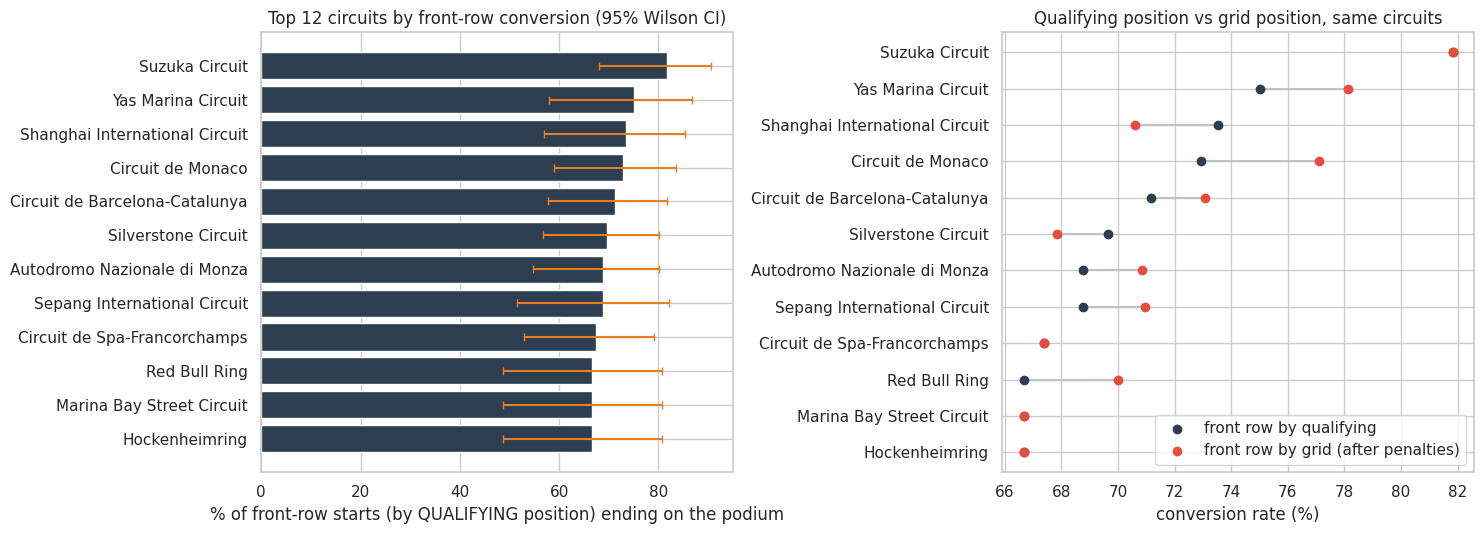

In [134]:
KEYS = ["circuitId", "circuit_name"]
MIN_ALL, MIN_ERA = 30, 20     # minimum front-row starts to rank a circuit overall / within an era

def conversion(df, flag, by):
    g = (df[df[flag]].groupby(by)["podium"].agg(front_starts="size", podiums="sum").reset_index())
    g["rate"] = g["podiums"] / g["front_starts"]
    g["lo"], g["hi"] = wilson(g["podiums"], g["front_starts"])
    return g

ov = conversion(q1, "front_quali", KEYS).merge(conversion(q1, "front_grid", KEYS),
                                               on=KEYS, suffixes=("_quali", "_grid"))
ranked = ov[ov["front_starts_quali"] >= MIN_ALL].sort_values("rate_quali", ascending=False).reset_index(drop=True)
ranked.index += 1
print(f"{len(ranked)} circuits with >= {MIN_ALL} front-row starts (of {len(ov)} with any)")
display(ranked[["circuit_name", "front_starts_quali", "rate_quali", "front_starts_grid", "rate_grid"]].round(3).head(15))

top = ranked.head(12).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.barh(top["circuit_name"], top["rate_quali"] * 100, color="#2c3e50",
        xerr=[(top["rate_quali"] - top["lo_quali"]) * 100, (top["hi_quali"] - top["rate_quali"]) * 100],
        error_kw=dict(ecolor="#e67e22", capsize=3))
ax.set_xlabel("% of front-row starts (by QUALIFYING position) ending on the podium")
ax.set_title("Top 12 circuits by front-row conversion (95% Wilson CI)")
ax = axes[1]
y = np.arange(len(top))
ax.hlines(y, top["rate_grid"] * 100, top["rate_quali"] * 100, color="#bdc3c7")
ax.scatter(top["rate_quali"] * 100, y, color="#2c3e50", label="front row by qualifying", zorder=3)
ax.scatter(top["rate_grid"] * 100, y, color="#e74c3c", label="front row by grid (after penalties)", zorder=3)
ax.set_yticks(y); ax.set_yticklabels(top["circuit_name"]); ax.set_xlabel("conversion rate (%)")
ax.set_title("Qualifying position vs grid position, same circuits"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Circuits compared (>= 20 front-row starts in BOTH eras): quali=7, grid=6
Spearman rank correlation pre vs hybrid:  qualifying def rho=-0.29 (p=0.527) | grid def rho=0.00 (p=1.000)
Overall front-row conversion: 1994-2013 = 64.7%, 2014-2024 = 73.7%


,circuit_name,front_starts_pre,rate_pre,rank_pre,front_starts_hy,rate_hy,rank_hy,rank_move,rate_change_pp
5,Circuit de Monaco,28,0.643,4,20,0.850,1,3,20.714
3,Circuit de Barcelona-Catalunya,30,0.633,5,22,0.818,2,3,18.485
10,Circuit de Spa-Francorchamps,24,0.542,7,22,0.818,2,5,27.652
7,Silverstone Circuit,32,0.656,1,24,0.750,4,-3,9.375
11,Autodromo Nazionale di Monza,26,0.654,2,22,0.727,5,-3,7.343
14,Autódromo José Carlos Pace,34,0.588,6,20,0.650,6,0,6.176
9,Hungaroring,26,0.654,2,22,0.591,7,-5,-6.294


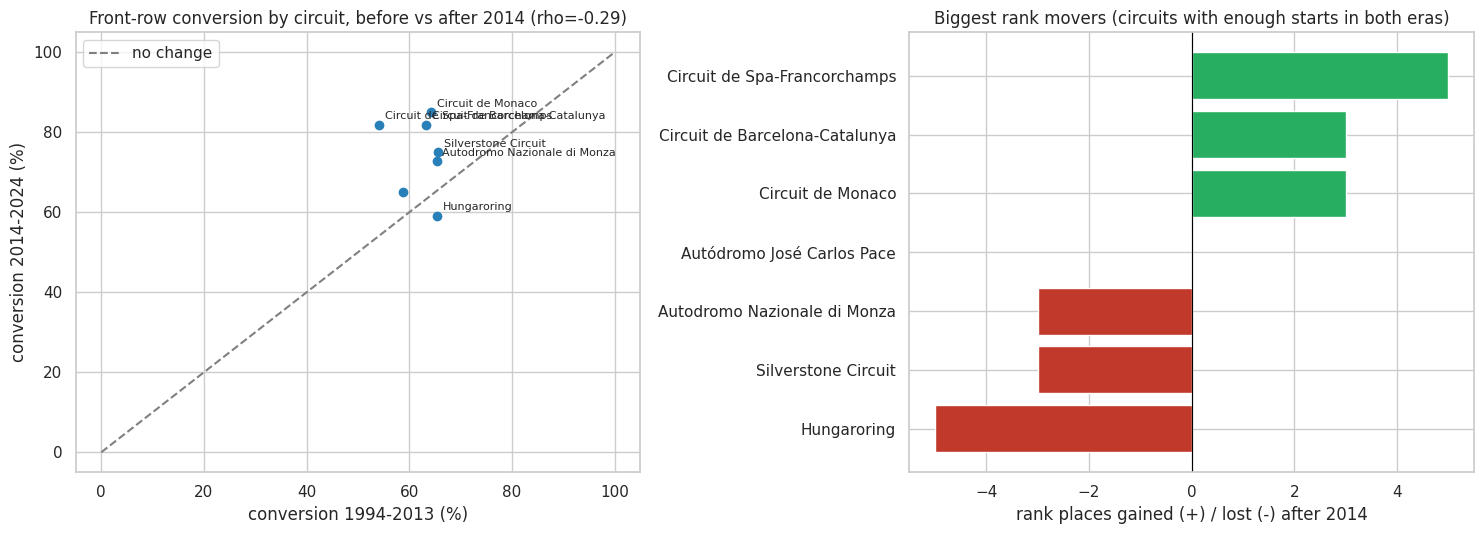

In [135]:
# Did the ranking change after 2014?
def era_table(flag):
    e = conversion(q1, flag, KEYS + ["era"])
    a = e[e["era"] == PRE].drop(columns="era").rename(columns=lambda c: c if c in KEYS else c + "_pre")
    b = e[e["era"] == HY].drop(columns="era").rename(columns=lambda c: c if c in KEYS else c + "_hy")
    t = a.merge(b, on=KEYS)                                    # circuits present in both eras
    t = t[(t["front_starts_pre"] >= MIN_ERA) & (t["front_starts_hy"] >= MIN_ERA)].copy()
    t["rank_pre"] = t["rate_pre"].rank(ascending=False, method="min").astype(int)
    t["rank_hy"] = t["rate_hy"].rank(ascending=False, method="min").astype(int)
    t["rank_move"] = t["rank_pre"] - t["rank_hy"]              # positive = climbed after 2014
    t["rate_change_pp"] = (t["rate_hy"] - t["rate_pre"]) * 100
    return t

era_q, era_g = era_table("front_quali"), era_table("front_grid")
rho_q, p_q = stats.spearmanr(era_q["rank_pre"], era_q["rank_hy"])
rho_g, p_g = stats.spearmanr(era_g["rank_pre"], era_g["rank_hy"])
print(f"Circuits compared (>= {MIN_ERA} front-row starts in BOTH eras): quali={len(era_q)}, grid={len(era_g)}")
print(f"Spearman rank correlation pre vs hybrid:  qualifying def rho={rho_q:.2f} (p={p_q:.3f}) | grid def rho={rho_g:.2f} (p={p_g:.3f})")
print(f"Overall front-row conversion: {PRE} = {q1[(q1.front_quali)&(q1.era==PRE)]['podium'].mean():.1%}, "
      f"{HY} = {q1[(q1.front_quali)&(q1.era==HY)]['podium'].mean():.1%}")

show = era_q.sort_values("rank_hy")[["circuit_name", "front_starts_pre", "rate_pre", "rank_pre",
                                     "front_starts_hy", "rate_hy", "rank_hy", "rank_move", "rate_change_pp"]]
display(show.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.scatter(era_q["rate_pre"] * 100, era_q["rate_hy"] * 100, color="#2980b9")
lim = [0, 100]; ax.plot(lim, lim, "--", color="grey", label="no change")
for _, r in era_q.reindex(era_q["rate_change_pp"].abs().sort_values(ascending=False).index).head(6).iterrows():
    ax.annotate(r["circuit_name"], (r["rate_pre"] * 100, r["rate_hy"] * 100), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel(f"conversion {PRE} (%)"); ax.set_ylabel(f"conversion {HY} (%)")
ax.set_title(f"Front-row conversion by circuit, before vs after 2014 (rho={rho_q:.2f})"); ax.legend()
ax = axes[1]
mv = era_q.reindex(era_q["rank_move"].abs().sort_values(ascending=False).index).head(10).sort_values("rank_move")
ax.barh(mv["circuit_name"], mv["rank_move"], color=np.where(mv["rank_move"] > 0, "#27ae60", "#c0392b"))
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("rank places gained (+) / lost (-) after 2014")
ax.set_title("Biggest rank movers (circuits with enough starts in both eras)")
plt.tight_layout(); plt.show()

In [136]:
# Auto-generated answer text (numbers come from the tables above)
t3 = ranked.head(3)
print("ANSWER Q1 - top circuits (front row by qualifying position, all years):")
for i, r in t3.iterrows():
    print(f"  {i}. {r['circuit_name']}: {r['rate_quali']:.1%} of {int(r['front_starts_quali'])} front-row starts ended on the podium")
print(f"\nANSWER Q1 - ranking change: Spearman rho between eras = {rho_q:.2f} on {len(era_q)} circuits "
      f"({'ranking is only moderately stable, so it does change after 2014' if rho_q < 0.6 else 'ranking is fairly stable across the 2014 boundary'}).")
up = era_q.sort_values("rank_move", ascending=False).iloc[0]; dn = era_q.sort_values("rank_move").iloc[0]
print(f"  Biggest climber: {up['circuit_name']} ({int(up['rank_move']):+d} places); biggest faller: {dn['circuit_name']} ({int(dn['rank_move']):+d} places).")
print(f"  Qualifying vs grid: {pen_share:.1%} of front-row qualifiers did not start on the front row, so the two definitions differ most where penalties are common.")

ANSWER Q1 - top circuits (front row by qualifying position, all years):
  1. Suzuka Circuit: 81.8% of 44 front-row starts ended on the podium
  2. Yas Marina Circuit: 75.0% of 32 front-row starts ended on the podium
  3. Shanghai International Circuit: 73.5% of 34 front-row starts ended on the podium

ANSWER Q1 - ranking change: Spearman rho between eras = -0.29 on 7 circuits (ranking is only moderately stable, so it does change after 2014).
  Biggest climber: Circuit de Spa-Francorchamps (+5 places); biggest faller: Hungaroring (-5 places).
  Qualifying vs grid: 3.8% of front-row qualifiers did not start on the front row, so the two definitions differ most where penalties are common.


**Write-up for the report (Q1).** Copy the `ANSWER Q1` lines above into the report and add: (i) the *winning circuits tend to be* those where overtaking is hard, a hypothesis to state as such, not a proven cause; (ii) *limitations*: qualifying records begin in 1994 so older eras are excluded, circuit layouts change over time, and rates for circuits with few races have wide intervals (shown as error bars).

### 7.2 Question 2: do drivers podium more often at their home country's circuit, after controlling for starting position?

**Join path:** `base` (driver, race) → `drivers.nationality` (a demonym such as "British") and `races → circuits.country` (e.g. "UK"). A demonym is not a country name, so we map nationality → country with an explicit dictionary and **print every nationality we could not map** instead of silently dropping it.

**Controlling for start position** (so the effect is not just "home drivers qualify better"):
1. *Stratified comparison*: home vs away podium rate **within the same grid band**.
2. *Logistic regression*: `podium ~ home + grid band (+ decade)`, standard errors clustered by driver (the same driver appears in many rows). We report the **odds ratio** for `home`.
3. *Robustness*: (a) only drivers who raced at home at least once (a fairer comparison group); (b) excluding the Indianapolis 500, which counted as a championship race in 1950-1960 and gives many American "home" starts that are not typical.

**Caveats to state in the report:** `drivers.nationality` is the driver's nationality as recorded today, not necessarily at the time of the race; home *team* effects (e.g. Ferrari in Italy) are not controlled; grid is the best available pre-race signal but not the only confounder (car quality).

In [137]:
NAT_TO_COUNTRY = {
    "American": "USA", "Argentine": "Argentina", "Australian": "Australia", "Austrian": "Austria",
    "Belgian": "Belgium", "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada",
    "Chinese": "China", "Dutch": "Netherlands", "French": "France", "German": "Germany",
    "Hungarian": "Hungary", "Indian": "India", "Italian": "Italy", "Japanese": "Japan",
    "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco", "Portuguese": "Portugal",
    "Russian": "Russia", "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden",
    "Swiss": "Switzerland", "Korean": "Korea", "Moroccan": "Morocco", "Emirati": "UAE", "Qatari": "Qatar",
}
COUNTRY_ALIAS = {"United Kingdom": "UK", "United States": "USA", "United Arab Emirates": "UAE", "South Korea": "Korea"}

q2 = (base.merge(circuits[["circuitId", "country"]].rename(columns={"country": "circuit_country"}),
                 on="circuitId", how="left", validate="m:1"))
q2["circuit_country"] = q2["circuit_country"].replace(COUNTRY_ALIAS)
q2["driver_country"] = q2["driver_nationality"].map(NAT_TO_COUNTRY)
q2["home"] = (q2["driver_country"] == q2["circuit_country"]).astype(int)

unmapped = (q2[q2["driver_country"].isna()].groupby("driver_nationality").size().sort_values(ascending=False))
print(f"Nationalities with no country mapping (treated as 'not home'): {len(unmapped)} nationalities, {int(unmapped.sum()):,} rows")
display(unmapped.head(15).to_frame("rows"))
print("Circuit countries that no driver nationality maps to:",
      sorted(set(q2["circuit_country"].dropna()) - set(NAT_TO_COUNTRY.values())))

n0 = len(q2)
q2 = q2[q2["grid"] >= 1].copy()          # grid 0 = pit-lane / no grid slot: start position undefined
print(f"\nDropped {n0 - len(q2):,} rows with grid = 0; modelling {len(q2):,} rows. Home starts: {int(q2['home'].sum()):,} "
      f"({q2['home'].mean():.1%}) by {q2.loc[q2.home == 1, 'driverId'].nunique()} drivers")

q2["grid_bin"] = pd.cut(q2["grid"], [0, 1, 2, 3, 5, 8, 12, 18, 99],
                        labels=["P1", "P2", "P3", "P4-5", "P6-8", "P9-12", "P13-18", "P19+"])
q2["decade"] = (q2["year"] // 10 * 10).astype(int).astype(str)

Nationalities with no country mapping (treated as 'not home'): 18 nationalities, 2,489 rows


,rows
driver_nationality,
Finnish,1193
New Zealander,407
Danish,221
Colombian,125
Thai,124
Venezuelan,120
Polish,99
Irish,92
Chilean,37


Circuit countries that no driver nationality maps to: ['Azerbaijan', 'Bahrain', 'Saudi Arabia', 'Singapore', 'Turkey']

Dropped 1,635 rows with grid = 0; modelling 25,033 rows. Home starts: 2,317 (9.3%) by 604 drivers


,away_n,home_n,away_rate,home_rate,diff_pp
grid_bin,,,,,
P1,1040,95,0.642,0.558,-8.441
P2,1034,90,0.561,0.511,-4.982
P3,1044,82,0.457,0.524,6.749
P4-5,2088,170,0.294,0.306,1.182
P6-8,3099,276,0.139,0.112,-2.644
P9-12,4107,392,0.054,0.059,0.511
P13-18,5990,588,0.018,0.010,-0.766
P19+,4314,624,0.005,0.010,0.452


,model,n,home_starts,odds_ratio,ci_low,ci_high,p_value
0,M0 naive: home only,25033,2317,0.794,0.675,0.936,0.006
1,M1 + grid band,25033,2317,0.930,0.770,1.122,0.448
2,M2 + grid band + decade (main model),25033,2317,0.933,0.766,1.136,0.488
3,"M3 M2, only drivers who raced at home",20882,2317,0.924,0.761,1.123,0.428
4,"M4 M2, excluding Indianapolis 500",24652,1937,0.929,0.759,1.137,0.473


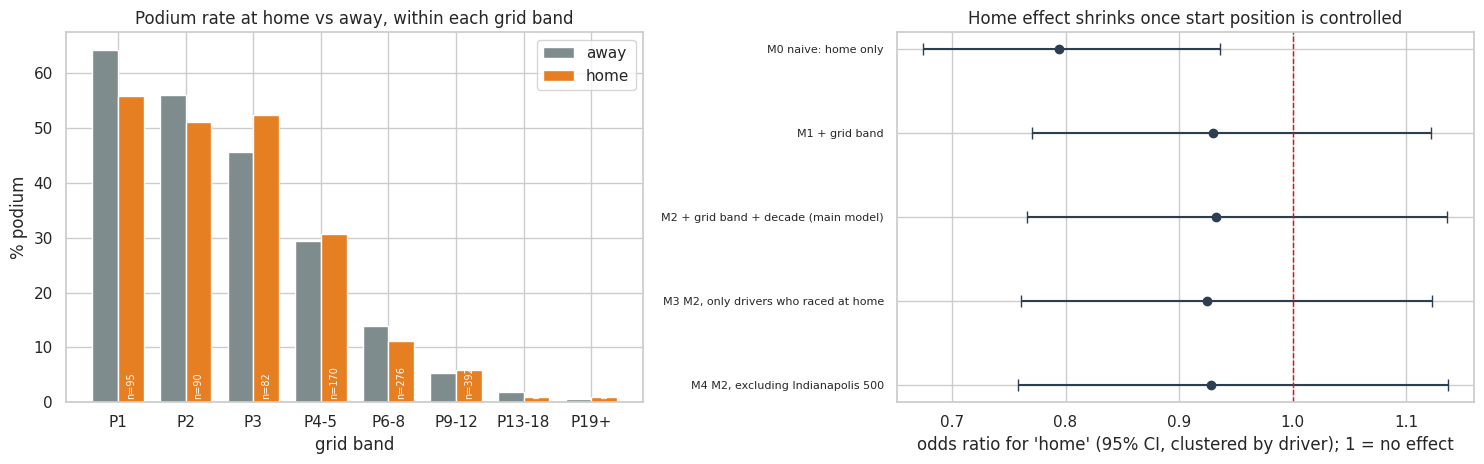

In [138]:
globals().pop("C", None)   # a stale variable named C (left by an earlier run) would shadow patsy's C() below
# (1) Stratified comparison: same grid band, home vs away
strat = (q2.groupby(["grid_bin", "home"])["podium"].agg(n="size", k="sum").reset_index())
w = strat.pivot(index="grid_bin", columns="home", values=["n", "k"])
tab = pd.DataFrame({"away_n": w[("n", 0)], "home_n": w[("n", 1)],
                    "away_rate": w[("k", 0)] / w[("n", 0)], "home_rate": w[("k", 1)] / w[("n", 1)]})
tab["diff_pp"] = (tab["home_rate"] - tab["away_rate"]) * 100
display(tab.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(tab)); wd = 0.38
axes[0].bar(x - wd / 2, tab["away_rate"] * 100, wd, label="away", color="#7f8c8d")
axes[0].bar(x + wd / 2, tab["home_rate"] * 100, wd, label="home", color="#e67e22")
axes[0].set_xticks(x); axes[0].set_xticklabels(tab.index.astype(str)); axes[0].set_xlabel("grid band")
axes[0].set_ylabel("% podium"); axes[0].set_title("Podium rate at home vs away, within each grid band"); axes[0].legend()
for i, (hn, an) in enumerate(zip(tab["home_n"], tab["away_n"])):
    axes[0].text(i + wd / 2, 1, f"n={int(hn)}", ha="center", fontsize=7, rotation=90, color="white")

# (2)+(3) Logistic regression with controls, clustered by driver
def fit_home(df, formula, label):
    m = smf.logit(formula, data=df).fit(disp=0, cov_type="cluster", cov_kwds={"groups": df["driverId"]})
    ci = np.exp(m.conf_int().loc["home"])
    return dict(model=label, n=int(m.nobs), home_starts=int(df["home"].sum()),
                odds_ratio=float(np.exp(m.params["home"])), ci_low=float(ci[0]), ci_high=float(ci[1]),
                p_value=float(m.pvalues["home"]))

home_drivers = set(q2.loc[q2["home"] == 1, "driverId"])
specs = [
    ("M0 naive: home only",                      q2, "podium ~ home"),
    ("M1 + grid band",                           q2, "podium ~ home + C(grid_bin)"),
    ("M2 + grid band + decade (main model)",     q2, "podium ~ home + C(grid_bin) + C(decade)"),
    ("M3 M2, only drivers who raced at home",    q2[q2["driverId"].isin(home_drivers)], "podium ~ home + C(grid_bin) + C(decade)"),
    ("M4 M2, excluding Indianapolis 500",        q2[q2["race_name"] != "Indianapolis 500"], "podium ~ home + C(grid_bin) + C(decade)"),
]
res_home = pd.DataFrame([fit_home(d, f, l) for l, d, f in specs])
display(res_home.round(3))

ax = axes[1]
yy = np.arange(len(res_home))[::-1]
ax.errorbar(res_home["odds_ratio"], yy, xerr=[res_home["odds_ratio"] - res_home["ci_low"], res_home["ci_high"] - res_home["odds_ratio"]],
            fmt="o", color="#2c3e50", capsize=4)
ax.axvline(1, color="red", ls="--", lw=1); ax.set_yticks(yy); ax.set_yticklabels(res_home["model"], fontsize=8)
ax.set_xlabel("odds ratio for 'home' (95% CI, clustered by driver); 1 = no effect")
ax.set_title("Home effect shrinks once start position is controlled")
plt.tight_layout(); plt.show()

In [139]:
m0, m2 = res_home.iloc[0], res_home.iloc[2]
sig = (m2["ci_low"] > 1) or (m2["ci_high"] < 1)
print(f"ANSWER Q2 - naive odds ratio (no control) = {m0['odds_ratio']:.2f}; after controlling for grid band and decade = "
      f"{m2['odds_ratio']:.2f} (95% CI {m2['ci_low']:.2f}-{m2['ci_high']:.2f}, p={m2['p_value']:.3f}).")
print("  => " + ("a home-circuit association remains after controlling for start position."
                 if sig else "the confidence interval includes 1, so after controlling for start position there is no clear home effect."))
print(f"  Robustness: only-home-drivers OR={res_home.iloc[3]['odds_ratio']:.2f}, excluding Indy 500 OR={res_home.iloc[4]['odds_ratio']:.2f}.")
print(f"  Based on {int(m2['home_starts']):,} home starts; an association, not proof that 'being at home' causes podiums.")

ANSWER Q2 - naive odds ratio (no control) = 0.79; after controlling for grid band and decade = 0.93 (95% CI 0.77-1.14, p=0.488).
  => the confidence interval includes 1, so after controlling for start position there is no clear home effect.
  Robustness: only-home-drivers OR=0.92, excluding Indy 500 OR=0.93.
  Based on 2,317 home starts; an association, not proof that 'being at home' causes podiums.


### 7.3 Question 3: which constructors have the highest mechanical-retirement rate, 2014-2021 vs 2022-2024?

**Definition (from the brief):** a mechanical retirement is a race **start** that ended early because a **component failed**. It excludes crashes, driver-caused retirements and regulation decisions.

**Join path:** `base` → `status` (the finishing-status text) → `constructors`.

**Choices:**
- `status` has no "mechanical" flag, so we classify every status text explicitly and **display the full classification table for the 2014-2024 statuses** so each decision can be checked. Statuses we did not review are printed, never guessed.
- Three tiers: **core mechanical** (engine, gearbox, hydraulics, ...), **ambiguous** (tyre, puncture, wing, "Retired" with no reason: could be damage from contact), and **non-mechanical** (accident, collision, disqualified, illness, ...). The **strict** answer uses core only; a **broad** version adds the ambiguous tier as a sensitivity check.
- **Denominator = race starts**, excluding entries that never started (did not qualify, withdrew).
- Teams that were renamed or bought are merged into one **franchise** (e.g. Force India → Racing Point → Aston Martin), otherwise a team like Aston Martin would have no 2014-2021 history. A constructor must have at least 60 starts in **both** periods to be compared.

,status_class,status_name,starts
8,finished,Finished,2403
0,finished,+1 Lap,1178
1,finished,+2 Laps,208
2,finished,+3 Laps,24
3,finished,+4 Laps,6
...,...,...,...
58,non_mechanical,Damage,2
59,non_mechanical,Debris,1
61,non_mechanical,Excluded,1
63,non_mechanical,Out of fuel,1


UNREVIEWED statuses (add them to one of the sets above if any appear): none


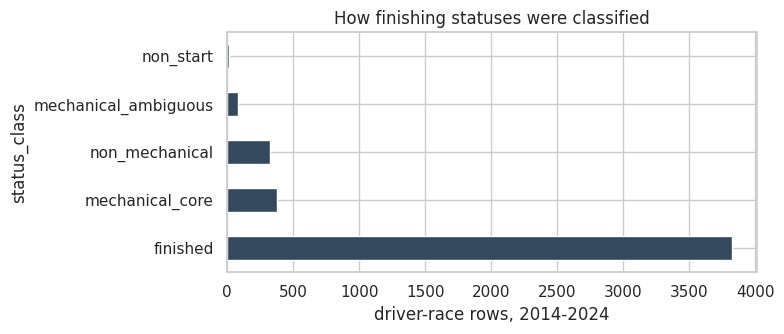

In [140]:
st = CLEAN["status"].rename(columns={"status": "status_name"})

MECH_CORE = {"Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension",
             "Brakes", "Differential", "Overheating", "Mechanical", "Oil leak", "Oil pressure", "Water leak",
             "Water pressure", "Fuel pressure", "Fuel pump", "Fuel system", "Fuel leak", "Throttle", "Steering",
             "Technical", "Electronics", "Exhaust", "Turbo", "Power Unit", "Power loss", "ERS", "Driveshaft",
             "Drivetrain", "Cooling system", "Vibrations", "Brake duct", "Engine fire", "Engine misfire",
             "Pneumatics", "Battery", "Alternator", "Crankshaft", "Ignition", "Injection", "Halfshaft",
             "Water pump", "Spark plugs", "Chassis", "Track rod", "Heat shield fire", "Magneto", "Distributor",
             "Crank", "Fuel"}
MECH_AMBIG = {"Puncture", "Tyre", "Wheel", "Wheel nut", "Wheel rim", "Front wing", "Rear wing", "Broken wing",
              "Undertray", "Driver Seat", "Seat", "Safety belt", "Handling", "Retired", "Refuelling"}
NON_MECH = {"Accident", "Collision", "Collision damage", "Spun off", "Disqualified", "Excluded", "Illness",
            "Driver unwell", "Fatal accident", "Safety concerns", "Physical", "Not classified", "Damage",
            "Debris", "Out of fuel", "Stalled", "Underweight"}
NON_START = {"Did not qualify", "Did not prequalify", "Withdrew", "Failed to qualify", "107% Rule"}

def classify(s):
    if s in ("Finished", "Lapped") or re.match(r"^\+\d+ Laps?$", s): return "finished"
    if s in NON_START: return "non_start"
    if s in MECH_CORE: return "mechanical_core"
    if s in MECH_AMBIG: return "mechanical_ambiguous"
    if s in NON_MECH: return "non_mechanical"
    return "UNREVIEWED"

w3 = (base[base["year"].between(2014, 2024)]
      .merge(st, on="statusId", how="left", validate="m:1"))
w3["status_name"] = w3["status_name"].fillna("UNKNOWN")
w3["status_class"] = w3["status_name"].map(classify)

review = (w3.groupby(["status_class", "status_name"]).size().rename("starts").reset_index()
            .sort_values(["status_class", "starts"], ascending=[True, False]))
display(review)
unrev = review[review["status_class"] == "UNREVIEWED"]
print("UNREVIEWED statuses (add them to one of the sets above if any appear):",
      unrev["status_name"].tolist() if len(unrev) else "none")

fig, ax = plt.subplots(figsize=(8, 3.5))
w3["status_class"].value_counts().plot.barh(ax=ax, color="#34495e")
ax.set_xlabel("driver-race rows, 2014-2024"); ax.set_title("How finishing statuses were classified"); plt.tight_layout(); plt.show()

,names merged
franchise,
Alpine (Lotus / Renault / Alpine),"[Lotus F1, Renault, Alpine F1 Team]"
Aston Martin (Force India / Racing Point),"[Force India, Racing Point, Aston Martin]"
Caterham,[Caterham]
Ferrari,[Ferrari]
Haas F1 Team,[Haas F1 Team]
Manor Marussia,[Manor Marussia]
Marussia,[Marussia]
McLaren,[McLaren]
Mercedes,[Mercedes]


Excluded for too few starts in one period: ['Caterham', 'Manor Marussia', 'Marussia']


,franchise,starts_a,strict_a,strict_rate_a,rank_a,starts_b,strict_b,strict_rate_b,rank_b,strict_change_pp,fisher_p,broad_rate_a,broad_rate_b
0,Alpine (Lotus / Renault / Alpine),319,43,0.135,3,136,15,0.110,1,-2.450,0.541,0.166,0.110
8,Sauber (Sauber / Alfa Romeo),320,26,0.081,5,136,12,0.088,2,0.699,0.853,0.100,0.103
6,RB (Toro Rosso / AlphaTauri / RB),320,47,0.147,1,136,8,0.059,3,-8.805,0.007,0.166,0.088
2,Ferrari,320,17,0.053,9,136,8,0.059,3,0.570,0.824,0.069,0.081
9,Williams,319,23,0.072,7,134,7,0.052,5,-1.986,0.537,0.094,0.082
3,Haas F1 Team,241,18,0.075,6,135,6,0.044,6,-3.024,0.281,0.120,0.052
5,Mercedes,320,12,0.038,10,136,6,0.044,7,0.662,0.794,0.047,0.044
1,Aston Martin (Force India / Racing Point),319,20,0.063,8,133,5,0.038,8,-2.510,0.369,0.075,0.060
4,McLaren,318,44,0.138,2,136,5,0.037,9,-10.160,0.001,0.160,0.037
7,Red Bull,319,34,0.107,4,136,5,0.037,9,-6.982,0.016,0.119,0.044


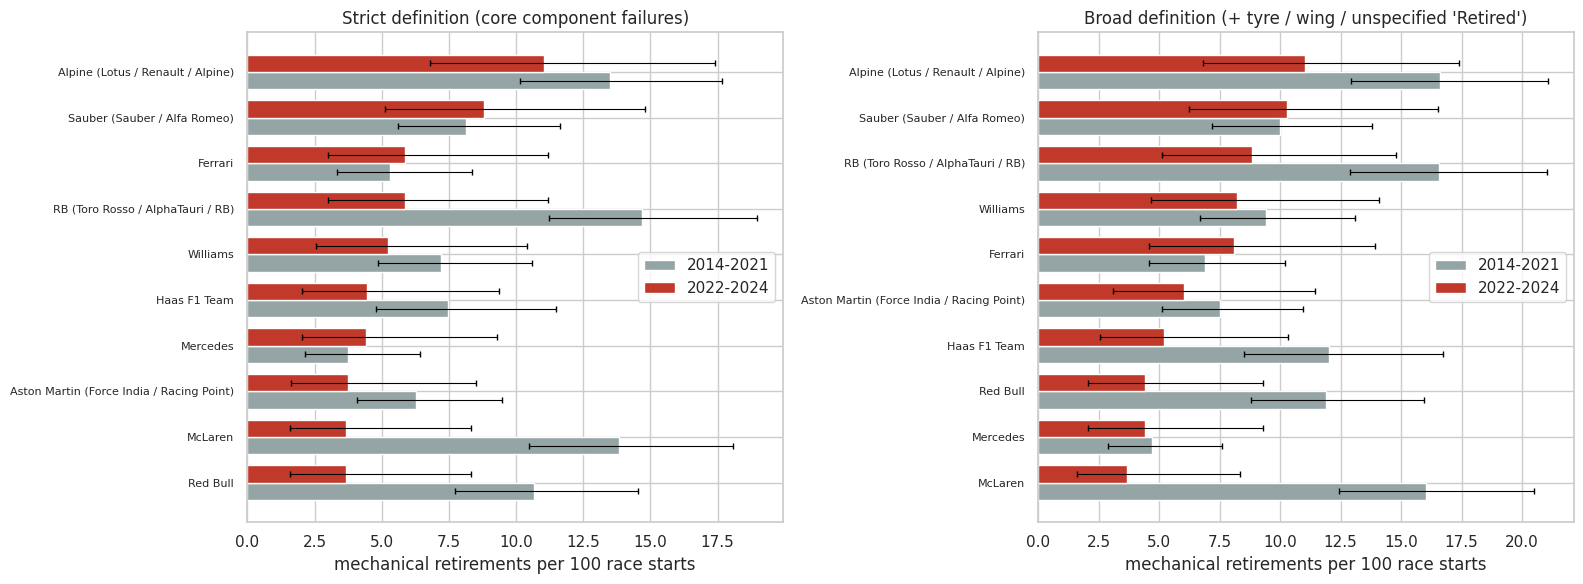

In [141]:
FRANCHISE = {
    "Force India": "Aston Martin (Force India / Racing Point)", "Racing Point": "Aston Martin (Force India / Racing Point)",
    "Aston Martin": "Aston Martin (Force India / Racing Point)",
    "Toro Rosso": "RB (Toro Rosso / AlphaTauri / RB)", "AlphaTauri": "RB (Toro Rosso / AlphaTauri / RB)",
    "RB F1 Team": "RB (Toro Rosso / AlphaTauri / RB)",
    "Sauber": "Sauber (Sauber / Alfa Romeo)", "Alfa Romeo": "Sauber (Sauber / Alfa Romeo)",
    "Kick Sauber": "Sauber (Sauber / Alfa Romeo)",
    "Renault": "Alpine (Lotus / Renault / Alpine)", "Lotus F1": "Alpine (Lotus / Renault / Alpine)",
    "Alpine F1 Team": "Alpine (Lotus / Renault / Alpine)", "Alpine": "Alpine (Lotus / Renault / Alpine)",
}
w3 = w3[w3["status_class"] != "non_start"].copy()
w3["franchise"] = w3["constructor_name"].map(lambda n: FRANCHISE.get(n, n))
PA, PB = "2014-2021", "2022-2024"
w3["period"] = np.where(w3["year"] <= 2021, PA, PB)
w3["mech_strict"] = w3["status_class"] == "mechanical_core"
w3["mech_broad"] = w3["status_class"].isin(["mechanical_core", "mechanical_ambiguous"])

display(w3.groupby("franchise")["constructor_name"].unique().to_frame("names merged"))

g = (w3.groupby(["franchise", "period"]).agg(starts=("raceId", "size"), strict=("mech_strict", "sum"),
                                              broad=("mech_broad", "sum")).reset_index())
a = g[g["period"] == PA].drop(columns="period").add_suffix("_a").rename(columns={"franchise_a": "franchise"})
b = g[g["period"] == PB].drop(columns="period").add_suffix("_b").rename(columns={"franchise_b": "franchise"})
MIN_STARTS = 60
t3 = a.merge(b, on="franchise")
print("Excluded for too few starts in one period:",
      sorted(set(g["franchise"]) - set(t3[(t3.starts_a >= MIN_STARTS) & (t3.starts_b >= MIN_STARTS)]["franchise"])))
t3 = t3[(t3["starts_a"] >= MIN_STARTS) & (t3["starts_b"] >= MIN_STARTS)].copy()

for kind in ["strict", "broad"]:
    for s in ["a", "b"]:
        t3[f"{kind}_rate_{s}"] = t3[f"{kind}_{s}"] / t3[f"starts_{s}"]
        t3[f"{kind}_lo_{s}"], t3[f"{kind}_hi_{s}"] = wilson(t3[f"{kind}_{s}"], t3[f"starts_{s}"])
    t3[f"{kind}_change_pp"] = (t3[f"{kind}_rate_b"] - t3[f"{kind}_rate_a"]) * 100
t3["rank_a"] = t3["strict_rate_a"].rank(ascending=False, method="min").astype(int)
t3["rank_b"] = t3["strict_rate_b"].rank(ascending=False, method="min").astype(int)
t3["fisher_p"] = [stats.fisher_exact([[r.strict_a, r.starts_a - r.strict_a], [r.strict_b, r.starts_b - r.strict_b]])[1]
                  for r in t3.itertuples()]

cols = ["franchise", "starts_a", "strict_a", "strict_rate_a", "rank_a", "starts_b", "strict_b", "strict_rate_b", "rank_b",
        "strict_change_pp", "fisher_p", "broad_rate_a", "broad_rate_b"]
display(t3.sort_values("strict_rate_b", ascending=False)[cols].round(3))

def rate_plot(ax, kind, title):
    d = t3.sort_values(f"{kind}_rate_b")
    y = np.arange(len(d)); h = 0.38
    for off, s, col, lab in [(-h / 2, "a", "#95a5a6", PA), (h / 2, "b", "#c0392b", PB)]:
        r = d[f"{kind}_rate_{s}"] * 100
        ax.barh(y + off, r, h, color=col, label=lab,
                xerr=[np.clip(r - d[f"{kind}_lo_{s}"] * 100, 0, None), np.clip(d[f"{kind}_hi_{s}"] * 100 - r, 0, None)],
                error_kw=dict(ecolor="black", lw=0.8, capsize=2))
    ax.set_yticks(y); ax.set_yticklabels(d["franchise"], fontsize=8)
    ax.set_xlabel("mechanical retirements per 100 race starts"); ax.set_title(title); ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
rate_plot(axes[0], "strict", "Strict definition (core component failures)")
rate_plot(axes[1], "broad", "Broad definition (+ tyre / wing / unspecified 'Retired')")
plt.tight_layout(); plt.show()

In [142]:
def top(df, col, n=3): return df.sort_values(col, ascending=False).head(n)
print(f"ANSWER Q3 - highest mechanical-retirement rate (strict), {PA}:")
for _, r in top(t3, "strict_rate_a").iterrows():
    print(f"  {r['franchise']}: {r['strict_rate_a']:.1%} ({int(r['strict_a'])} of {int(r['starts_a'])} starts)")
print(f"ANSWER Q3 - highest mechanical-retirement rate (strict), {PB}:")
for _, r in top(t3, "strict_rate_b").iterrows():
    print(f"  {r['franchise']}: {r['strict_rate_b']:.1%} ({int(r['strict_b'])} of {int(r['starts_b'])} starts)")
best, worst = t3.sort_values("strict_change_pp").iloc[0], t3.sort_values("strict_change_pp").iloc[-1]
print(f"Biggest improvement: {best['franchise']} ({best['strict_change_pp']:+.1f} pp, Fisher p={best['fisher_p']:.3f}); "
      f"biggest deterioration: {worst['franchise']} ({worst['strict_change_pp']:+.1f} pp, Fisher p={worst['fisher_p']:.3f}).")
rho3, _ = stats.spearmanr(t3["strict_rate_a"], t3["strict_rate_b"])
print(f"Rank agreement between periods (Spearman, strict) = {rho3:.2f}; fleet-wide strict rate "
      f"{w3[w3.period == PA]['mech_strict'].mean():.1%} -> {w3[w3.period == PB]['mech_strict'].mean():.1%}.")

ANSWER Q3 - highest mechanical-retirement rate (strict), 2014-2021:
  RB (Toro Rosso / AlphaTauri / RB): 14.7% (47 of 320 starts)
  McLaren: 13.8% (44 of 318 starts)
  Alpine (Lotus / Renault / Alpine): 13.5% (43 of 319 starts)
ANSWER Q3 - highest mechanical-retirement rate (strict), 2022-2024:
  Alpine (Lotus / Renault / Alpine): 11.0% (15 of 136 starts)
  Sauber (Sauber / Alfa Romeo): 8.8% (12 of 136 starts)
  RB (Toro Rosso / AlphaTauri / RB): 5.9% (8 of 136 starts)
Biggest improvement: McLaren (-10.2 pp, Fisher p=0.001); biggest deterioration: Sauber (Sauber / Alfa Romeo) (+0.7 pp, Fisher p=0.853).
Rank agreement between periods (Spearman, strict) = 0.09; fleet-wide strict rate 9.2% -> 5.7%.


**Write-up for the report (Q3).** Copy the `ANSWER Q3` lines and add the limitations: (i) a constructor's reliability partly reflects its **power-unit supplier** (customer teams share a manufacturer's engine), so this is a team-level, not purely chassis-level, rate; (ii) only ~3 seasons in 2022-2024, so intervals are wide and small differences are not significant (use the Fisher p-values and error bars); (iii) the status text is free-form, so the strict/broad pair brackets the classification uncertainty; (iv) the 2014-2021 and 2022-2024 periods also differ in the regulations (new floor/cost-cap era), so a change is not attributable to one cause.

### 7.4 Section 7 summary and hand-off to Section 8

| Question | Method | Output to carry into the report |
|---|---|---|
| Q1 | front-row conversion by circuit, qualifying vs grid, pre/post-2014, Wilson CIs, Spearman | top circuits, rank-stability statistic, penalty share |
| Q2 | stratified home/away comparison + clustered logistic regression, 3 robustness checks | odds ratio before and after controlling for grid |
| Q3 | explicit status classification table, strict vs broad, franchise merge, Fisher test | highest-rate constructors in each period, change and uncertainty |

**Observations to use in Section 8 (features):** grid and qualifying are pre-race and strongly related to podium (Q1); a home flag is pre-race but its effect is small once grid is controlled (Q2, check the numbers); constructor reliability varies by period, so *recent* constructor form should be used rather than all-time averages (Q3). Section 8 must test these ideas, not assume them.

## 8. Feature engineering (leakage-safe) and splitting

**Prediction cutoff:** after qualifying, before the race starts. A feature is allowed only if its value was already known at that moment.

| Group | Features | Why it is known before the race |
|---|---|---|
| `grid` | `grid_num`, `grid_pit` | the starting grid is set after qualifying and penalties; a pit-lane start (grid 0) is moved to "last + 1" and flagged |
| `qualifying` | `q_pos`, `q_gap_pct`, `has_quali`, `grid_vs_quali` | qualifying is finished before the race; `grid_vs_quali` captures penalties; `has_quali` flags the era with no qualifying record |
| `driver_form` | `drv_podium_rate`, `drv_finish_frac`, `drv_starts_before`, `drv_podiums_career` | rolling statistics of the driver's **previous** races only (`shift(1)` before any rolling window) |
| `team_form` | `con_podium_rate`, `con_finish_frac` | same idea for the constructor, over its previous races |
| `standings` | `ds_points_frac`, `ds_pos`, `ds_wins`, `cs_points_frac`, `cs_pos`, `cs_wins` | standings **after the previous round** of the same season (the table stores standings *after* each race, so the current race's row must not be used) |
| `context` | `field_size`, `round`, `age`, `is_home` | entry list, calendar position, date of birth and circuit country are all known in advance |

**Never used as features** (known only after the race): `position`, `positionOrder`, `points`, `laps`, `time`, `milliseconds`, fastest-lap fields, `statusId`, pit stops, lap times and the current race's standings. Identity columns (`driverId`, `constructorId`) are also excluded: they have hundreds of levels and would let a model memorise people instead of learning pre-race signals.

,driver_podium_rate AUC,team_podium_rate AUC,mean AUC
window,,,
3,0.7717,0.8072,0.7895
5,0.8084,0.8268,0.8176
10,0.8312,0.8387,0.8350


Chosen form window W = 10 races (highest mean univariate ROC-AUC on training rows).


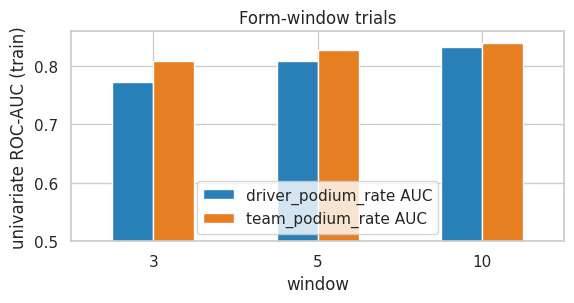

Modeling table: 26,668 rows (one per driver per race) | 22 features in 6 groups


,group,feature,missing_%
0,grid,grid_num,0.0
1,grid,grid_pit,0.0
2,qualifying,q_pos,60.6
3,qualifying,q_gap_pct,61.2
4,qualifying,has_quali,0.0
5,qualifying,grid_vs_quali,60.6
6,driver_form,drv_podium_rate,3.2
7,driver_form,drv_finish_frac,3.2
8,driver_form,drv_starts_before,0.0
9,driver_form,drv_podiums_career,0.0


In [143]:
from sklearn.metrics import roc_auc_score

# Chronological split (justified in 8.3): train <= 2016 | validation 2017-2020 | test 2021-2024
TRAIN_END, VAL_END = 2016, 2020

FORBIDDEN = {"position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds", "fastestLap",
             "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "podium", "finish_frac"}

fe = (base[["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date", "dob",
            "driver_nationality", "grid", "positionOrder", "podium"]]
      .sort_values(["date", "raceId", "driverId"]).reset_index(drop=True))
assert not fe.duplicated(["raceId", "driverId"]).any()

# ---- grid and field size ------------------------------------------------------------
fe["field_size"] = fe.groupby("raceId")["driverId"].transform("size").astype(float)
fe["finish_frac"] = fe["positionOrder"] / fe["field_size"]          # used ONLY through past races (shifted)
fe["grid_pit"] = (fe["grid"] == 0).astype(int)
fe["grid_num"] = np.where(fe["grid"] > 0, fe["grid"], fe["field_size"] + 1).astype(float)

# ---- qualifying ----------------------------------------------------------------------
qf = (CLEAN["qualifying"].sort_values("qualifyId").drop_duplicates(["raceId", "driverId"])
      [["raceId", "driverId", "position", "q1", "q2", "q3"]].rename(columns={"position": "q_pos"}))
qf["q_best"] = qf[["q1", "q2", "q3"]].min(axis=1)                    # best lap the driver set in any session
qf["q_gap_pct"] = 100 * (qf["q_best"] / qf.groupby("raceId")["q_best"].transform("min") - 1)
fe = fe.merge(qf[["raceId", "driverId", "q_pos", "q_gap_pct"]], on=["raceId", "driverId"], how="left", validate="1:1")
fe["has_quali"] = fe["q_pos"].notna().astype(int)
fe["grid_vs_quali"] = fe["grid_num"] - fe["q_pos"]

# ---- form features: strictly past races ---------------------------------------------
def driver_form(df, w):
    g = df.groupby("driverId", sort=False)
    out = pd.DataFrame(index=df.index)
    out["drv_podium_rate"] = g["podium"].transform(lambda s: s.shift(1).rolling(w, min_periods=1).mean())
    out["drv_finish_frac"] = g["finish_frac"].transform(lambda s: s.shift(1).rolling(w, min_periods=1).mean())
    return out

team_race = (fe.groupby(["constructorId", "raceId"], as_index=False)
               .agg(date=("date", "first"), pod=("podium", "sum"), n=("podium", "size"), fin=("finish_frac", "mean"))
               .sort_values(["constructorId", "date", "raceId"]).reset_index(drop=True))

def team_form(tr, w):
    g = tr.groupby("constructorId", sort=False)
    pod = g["pod"].transform(lambda s: s.shift(1).rolling(w, min_periods=1).sum())
    n = g["n"].transform(lambda s: s.shift(1).rolling(w, min_periods=1).sum())
    out = tr[["constructorId", "raceId"]].copy()
    out["con_podium_rate"] = pod / n
    out["con_finish_frac"] = g["fin"].transform(lambda s: s.shift(1).rolling(w, min_periods=1).mean())
    return out

def uni_auc(x, yv):
    x = pd.Series(x).reset_index(drop=True); yv = pd.Series(yv).reset_index(drop=True)
    ok = x.notna()
    if ok.sum() < 50 or yv[ok].nunique() < 2:
        return np.nan
    return roc_auc_score(yv[ok], x[ok])

# Empirical choice of the rolling window (trial record: candidates 3, 5, 10 races), judged on TRAIN rows only
tr_mask = (fe["year"] <= TRAIN_END).values
trial_rows = []
for w in [3, 5, 10]:
    d = driver_form(fe, w)
    t = fe[["constructorId", "raceId"]].merge(team_form(team_race, w), on=["constructorId", "raceId"], how="left")
    trial_rows.append({"window": w,
                       "driver_podium_rate AUC": uni_auc(d["drv_podium_rate"][tr_mask], fe["podium"][tr_mask]),
                       "team_podium_rate AUC": uni_auc(t["con_podium_rate"][tr_mask], fe["podium"][tr_mask])})
window_trials = pd.DataFrame(trial_rows).set_index("window")
window_trials["mean AUC"] = window_trials.mean(axis=1)
W = int(window_trials["mean AUC"].idxmax())
display(window_trials.round(4))
print(f"Chosen form window W = {W} races (highest mean univariate ROC-AUC on training rows).")

fig, ax = plt.subplots(figsize=(6, 3.2))
window_trials[["driver_podium_rate AUC", "team_podium_rate AUC"]].plot.bar(ax=ax, rot=0, color=["#2980b9", "#e67e22"])
ax.set_ylim(0.5, window_trials.iloc[:, :2].max().max() + 0.02); ax.set_ylabel("univariate ROC-AUC (train)")
ax.set_title("Form-window trials"); plt.tight_layout(); plt.show()

fe = pd.concat([fe, driver_form(fe, W)], axis=1)
fe = fe.merge(team_form(team_race, W), on=["constructorId", "raceId"], how="left", validate="m:1")
fg = fe.groupby("driverId", sort=False)
fe["drv_starts_before"] = fg.cumcount().astype(float)                       # races already started
fe["drv_podiums_career"] = (fg["podium"].cumsum() - fe["podium"]).astype(float)   # podiums BEFORE this race

# ---- standings after the PREVIOUS round of the same season ---------------------------
def pre_race_standings(table, key, prefix):
    s = CLEAN[table][["raceId", key, "points", "position", "wins"]].drop_duplicates(["raceId", key])
    s = s.merge(races[["raceId", "year", "date"]], on="raceId").sort_values(["date", "raceId"])
    g = s.groupby([key, "year"], sort=False)
    for c, new in [("points", f"{prefix}_points"), ("position", f"{prefix}_pos"), ("wins", f"{prefix}_wins")]:
        s[new] = g[c].shift(1)                    # shift: value after the previous recorded race, never the current one
    return s[["raceId", key, f"{prefix}_points", f"{prefix}_pos", f"{prefix}_wins"]]

fe = fe.merge(pre_race_standings("driver_standings", "driverId", "ds"), on=["raceId", "driverId"], how="left", validate="1:1")
fe = fe.merge(pre_race_standings("constructor_standings", "constructorId", "cs"), on=["raceId", "constructorId"], how="left", validate="m:1")
for pfx in ["ds", "cs"]:
    fe[f"{pfx}_points"] = fe[f"{pfx}_points"].fillna(0.0)     # nothing earned yet (round 1 / no earlier row)
    fe[f"{pfx}_wins"] = fe[f"{pfx}_wins"].fillna(0.0)
    leader = fe.groupby("raceId")[f"{pfx}_points"].transform("max")
    fe[f"{pfx}_points_frac"] = np.where(leader > 0, fe[f"{pfx}_points"] / leader, 0.0)   # era-free scale (points systems changed)

# ---- context -------------------------------------------------------------------------
circ_country = CLEAN["circuits"][["circuitId", "country"]].rename(columns={"country": "circuit_country"})
fe = fe.merge(circ_country, on="circuitId", how="left", validate="m:1")
fe["circuit_country"] = fe["circuit_country"].replace(COUNTRY_ALIAS)
fe["is_home"] = (fe["driver_nationality"].map(NAT_TO_COUNTRY) == fe["circuit_country"]).astype(int)
fe["age"] = (fe["date"] - fe["dob"]).dt.days / 365.25
fe["round"] = fe["round"].astype(float)

GROUPS = {
    "grid": ["grid_num", "grid_pit"],
    "qualifying": ["q_pos", "q_gap_pct", "has_quali", "grid_vs_quali"],
    "driver_form": ["drv_podium_rate", "drv_finish_frac", "drv_starts_before", "drv_podiums_career"],
    "team_form": ["con_podium_rate", "con_finish_frac"],
    "standings": ["ds_points_frac", "ds_pos", "ds_wins", "cs_points_frac", "cs_pos", "cs_wins"],
    "context": ["field_size", "round", "age", "is_home"],
}
FEATURES = [c for cols in GROUPS.values() for c in cols]
assert len(FEATURES) == len(set(FEATURES)) and all(c in fe.columns for c in FEATURES)
assert not (set(FEATURES) & FORBIDDEN), "a post-race column slipped into the feature list"
assert len(fe) == len(base) and not fe.duplicated(["raceId", "driverId"]).any()

print(f"Modeling table: {fe.shape[0]:,} rows (one per driver per race) | {len(FEATURES)} features in {len(GROUPS)} groups")
display(pd.DataFrame({"group": [g for g, c in GROUPS.items() for _ in c], "feature": FEATURES,
                      "missing_%": [round(100 * fe[c].isna().mean(), 1) for c in FEATURES]}))

### 8.1 Leakage tests
Three checks that the form and standings features use only past information:
1. no forbidden (post-race) column is in the feature list (asserted above);
2. a brute-force recomputation of `drv_podium_rate` for 300 random rows from past rows only must match exactly;
3. changing one race's outcome must not change the features of that race or any earlier race (perturbation test).

In [144]:
# Test 2: brute force, past rows only
chk = fe.sample(300, random_state=SEED)
bad = 0
for i, r in chk.iterrows():
    past = fe.iloc[:i]
    past = past[past["driverId"] == r["driverId"]].tail(W)
    exp = past["podium"].mean() if len(past) else np.nan
    got = r["drv_podium_rate"]
    if not ((np.isnan(exp) and np.isnan(got)) or abs(exp - got) < 1e-9):
        bad += 1
print(f"Brute-force check of drv_podium_rate on 300 rows: mismatches = {bad}")
assert bad == 0

# Test 3: perturbation. Flip the outcome of ONE race (the 10th race of 2019). Features of that race and of every
# earlier race must not change (no leakage from the current outcome); only LATER races may change.
r0 = fe.loc[fe["year"] == 2019, "raceId"].drop_duplicates().iloc[9]
d0 = fe.loc[fe["raceId"] == r0, "date"].iloc[0]
pert = fe[["driverId", "constructorId", "raceId", "year", "date", "podium", "finish_frac"]].copy()
m0 = pert["raceId"] == r0
pert.loc[m0, "podium"] = 1 - pert.loc[m0, "podium"]
pert.loc[m0, "finish_frac"] = 1 - pert.loc[m0, "finish_frac"]
dp = driver_form(pert, W)
upto = (fe["date"] <= d0).values
later = ~upto
unchanged_upto = np.allclose(dp.loc[upto, "drv_podium_rate"].fillna(-1), fe.loc[upto, "drv_podium_rate"].fillna(-1))
changed_later = not np.allclose(dp.loc[later, "drv_podium_rate"].fillna(-1), fe.loc[later, "drv_podium_rate"].fillna(-1))
print("Perturbation test (flip the outcome of one 2019 race):")
print("  features up to and including that race unchanged:", unchanged_upto)
print("  features of later races DO change (test is sensitive):", changed_later)
assert unchanged_upto and changed_later
print("Leakage tests passed.")

Brute-force check of drv_podium_rate on 300 rows: mismatches = 0
Perturbation test (flip the outcome of one 2019 race):
  features up to and including that race unchanged: True
  features of later races DO change (test is sensitive): True
Leakage tests passed.


### 8.2 Chronological split (train / validation / test)
**Choice:** train on seasons **<= 2016**, validate on **2017-2020**, test on **2021-2024**.

Why chronological and not random:
- A random split would put races from the same weekend (and the same season's form and standings values) in both train and test, so the score would be inflated by leakage across rows that are not independent.
- In real use we predict *future* races from the past, so the test must be the future. The validation block sits between train and test so hyperparameters and thresholds are tuned on data older than the test.
- The test block (2021-2024) includes the 2022 regulation change, which makes it a hard, honest test of drift.
- Validation and test each hold about four seasons, large enough for stable estimates of a 12-13% positive class.

,rows,podiums,podium_rate,first_year,last_year,races
split,,,,,,
train,23289,2871,0.1233,1950,2016,956
val,1580,237,0.1500,2017,2020,79
test,1799,270,0.1501,2021,2024,90


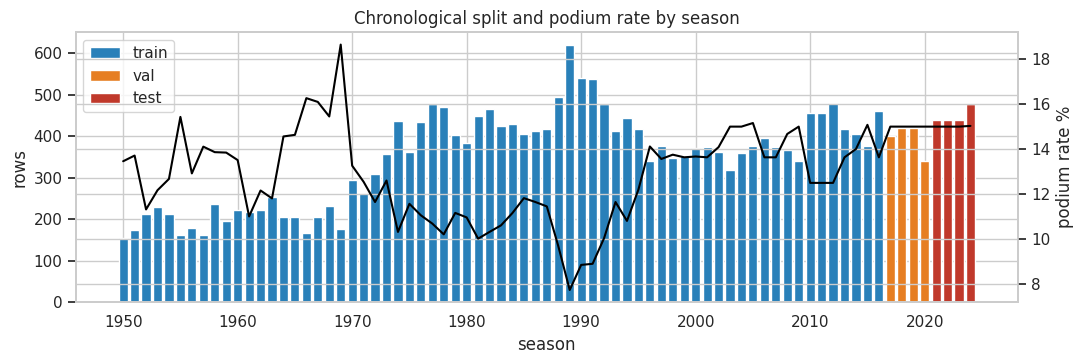

In [145]:
fe["split"] = np.where(fe["year"] <= TRAIN_END, "train", np.where(fe["year"] <= VAL_END, "val", "test"))
meta = fe[["raceId", "driverId", "year", "split"]].merge(
    base[["raceId", "driverId", "surname", "race_name", "constructor_name"]], on=["raceId", "driverId"], how="left", validate="1:1")

split_tbl = fe.groupby("split").agg(rows=("podium", "size"), podiums=("podium", "sum"), podium_rate=("podium", "mean"),
                                    first_year=("year", "min"), last_year=("year", "max"), races=("raceId", "nunique")).loc[["train", "val", "test"]]
display(split_tbl.round(4))

X_train, y_train = fe.loc[fe.split == "train", FEATURES], fe.loc[fe.split == "train", "podium"]
X_val,   y_val   = fe.loc[fe.split == "val", FEATURES],   fe.loc[fe.split == "val", "podium"]
X_test,  y_test  = fe.loc[fe.split == "test", FEATURES],  fe.loc[fe.split == "test", "podium"]
meta_test = meta[meta.split == "test"]

colors = {"train": "#2980b9", "val": "#e67e22", "test": "#c0392b"}
fig, ax = plt.subplots(figsize=(11, 3.8))
cnt = fe.groupby(["year", "split"]).size().unstack("split").fillna(0)
for s in ["train", "val", "test"]:
    ax.bar(cnt.index, cnt[s], color=colors[s], label=s)
ax2 = ax.twinx()
pr = fe.groupby("year")["podium"].mean() * 100
ax2.plot(pr.index, pr.values, color="black", lw=1.5, label="podium rate %")
ax2.set_ylabel("podium rate %"); ax.set_ylabel("rows"); ax.set_xlabel("season")
ax.set_title("Chronological split and podium rate by season"); ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

### 8.3 Evidence for each feature group
Each group is first justified by exploratory evidence (below, **training rows only**), and later its real contribution is measured by ablation (Section 10).
- **Univariate ROC-AUC:** how well one feature alone ranks podium finishers above the rest (0.5 means no signal).
- **Podium rate by feature bin:** shows the shape of the relation.
- **Correlation heatmap:** shows which features carry overlapping information.
- **Missingness by era:** shows which features are only partly available.

,group,feature,auc,strength,direction,missing_%
2,qualifying,q_pos,0.098,0.902,higher -> fewer podiums,69.4
0,grid,grid_num,0.112,0.888,higher -> fewer podiums,0.0
3,qualifying,q_gap_pct,0.123,0.877,higher -> fewer podiums,69.9
13,standings,ds_pos,0.159,0.841,higher -> fewer podiums,15.0
10,team_form,con_podium_rate,0.839,0.839,higher -> more podiums,1.4
16,standings,cs_pos,0.169,0.831,higher -> fewer podiums,14.4
6,driver_form,drv_podium_rate,0.831,0.831,higher -> more podiums,3.6
11,team_form,con_finish_frac,0.189,0.811,higher -> fewer podiums,1.4
7,driver_form,drv_finish_frac,0.192,0.808,higher -> fewer podiums,3.6
12,standings,ds_points_frac,0.794,0.794,higher -> more podiums,0.0


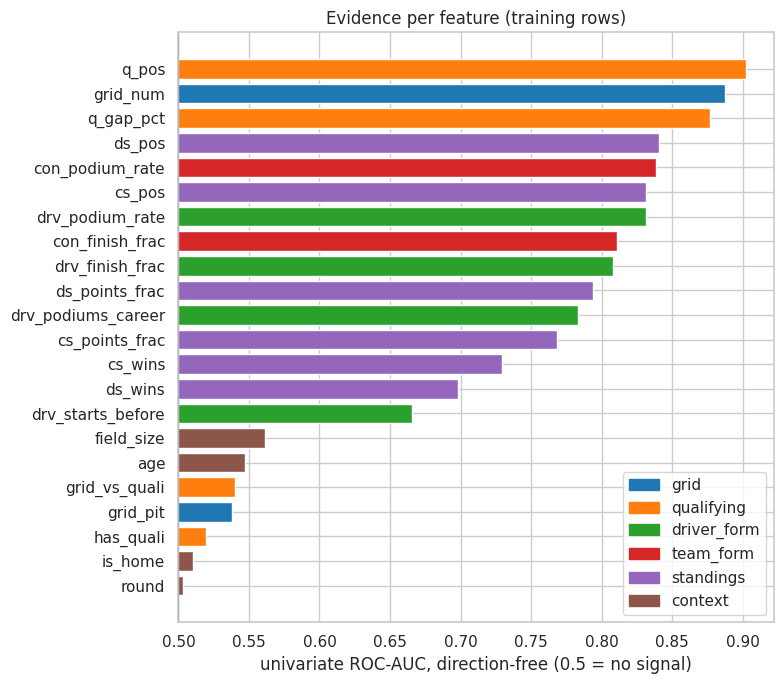

In [146]:
rows = []
for g, cols in GROUPS.items():
    for c in cols:
        a = uni_auc(X_train[c], y_train)
        rows.append({"group": g, "feature": c, "auc": a, "strength": max(a, 1 - a) if a == a else np.nan,
                     "direction": "higher -> more podiums" if a > 0.5 else "higher -> fewer podiums",
                     "missing_%": round(100 * X_train[c].isna().mean(), 1)})
uni = pd.DataFrame(rows).sort_values("strength", ascending=False)
display(uni.round(3))

pal = dict(zip(GROUPS, sns.color_palette("tab10", len(GROUPS))))
fig, ax = plt.subplots(figsize=(8, 7))
u = uni.iloc[::-1]
ax.barh(u["feature"], u["strength"] - 0.5, left=0.5, color=[pal[g] for g in u["group"]])
ax.axvline(0.5, color="k", lw=0.8)
ax.set_xlabel("univariate ROC-AUC, direction-free (0.5 = no signal)")
ax.set_title("Evidence per feature (training rows)")
handles = [plt.Rectangle((0, 0), 1, 1, color=pal[g]) for g in GROUPS]
ax.legend(handles, GROUPS.keys(), loc="lower right"); plt.tight_layout(); plt.show()

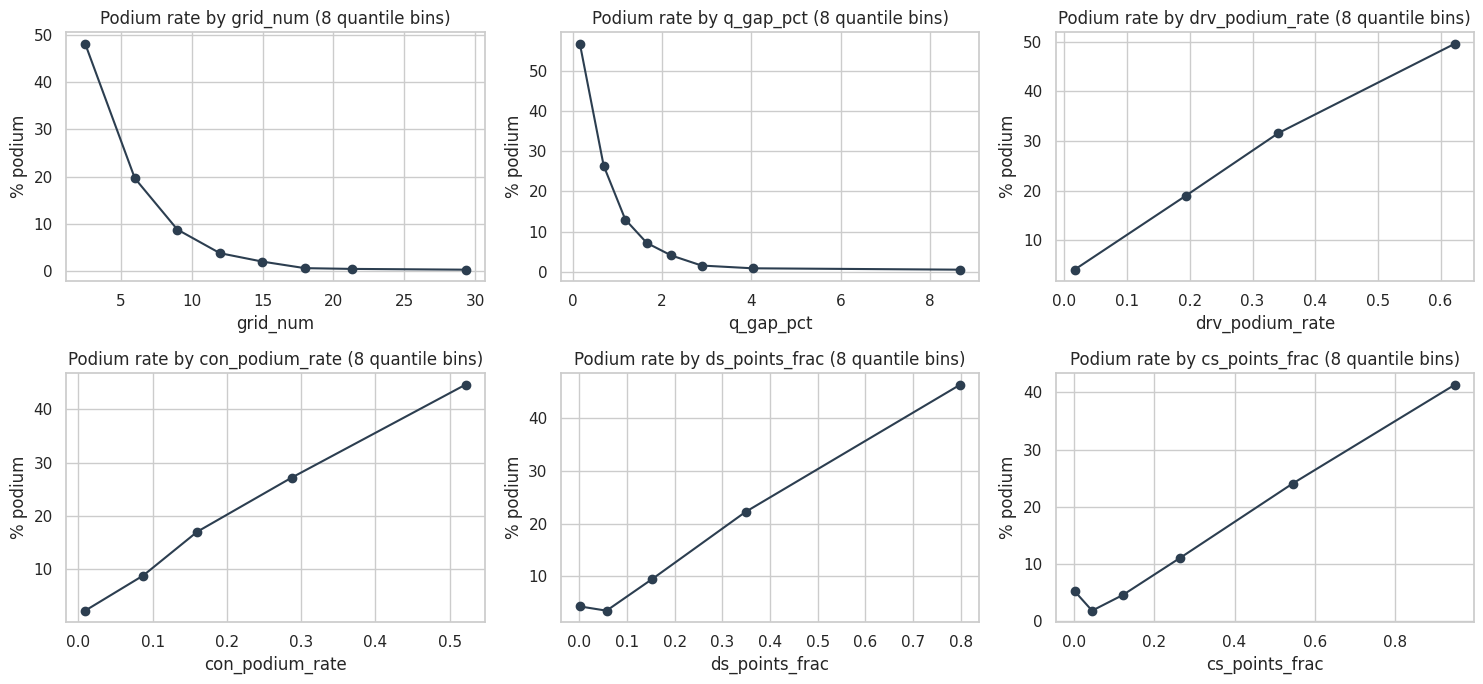

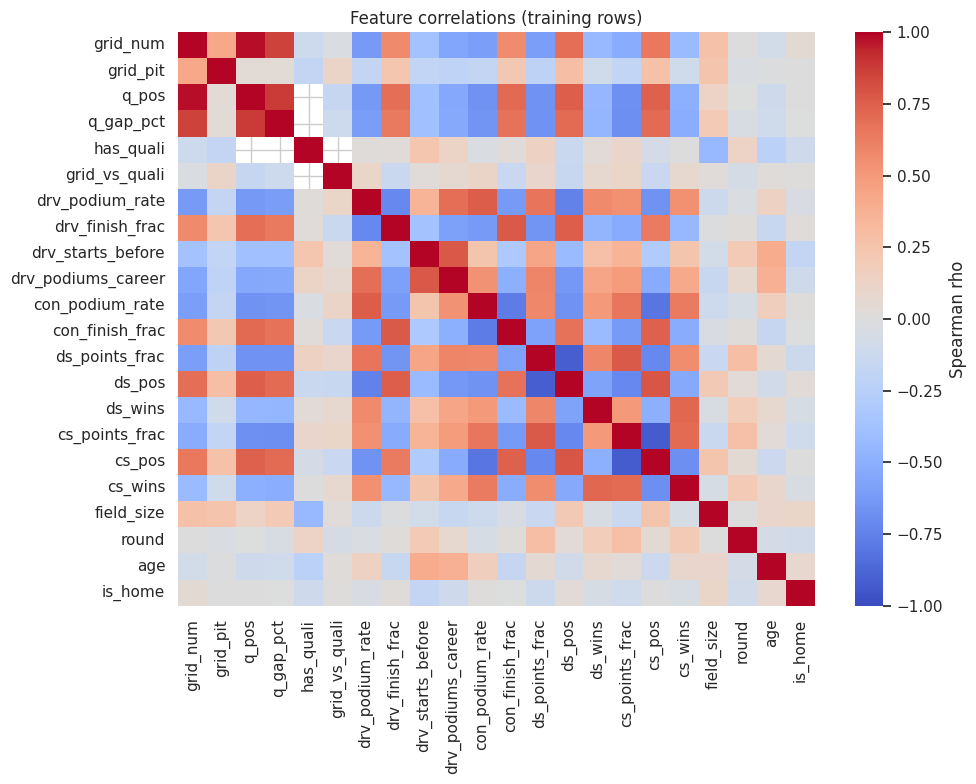

Highly correlated pairs (|rho| >= 0.8): they overlap in information, so single-feature importance must be read with care.


,level_0,level_1,rho
1,grid_num,q_pos,0.98
207,cs_points_frac,cs_pos,-0.92
183,ds_points_frac,ds_pos,-0.91
41,q_pos,q_gap_pct,0.88
2,grid_num,q_gap_pct,0.86
167,con_podium_rate,cs_pos,-0.81


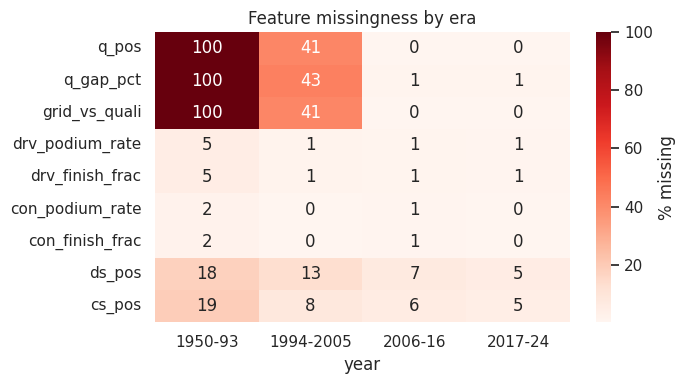

In [147]:
key = ["grid_num", "q_gap_pct", "drv_podium_rate", "con_podium_rate", "ds_points_frac", "cs_points_frac"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), key):
    d = pd.DataFrame({"x": X_train[c], "y": y_train}).dropna()
    d["bin"] = pd.qcut(d["x"], 8, duplicates="drop")
    t = d.groupby("bin", observed=True).agg(rate=("y", "mean"), xm=("x", "mean"), n=("y", "size"))
    ax.plot(t["xm"], 100 * t["rate"], marker="o", color="#2c3e50")
    ax.set_xlabel(c); ax.set_ylabel("% podium"); ax.set_title(f"Podium rate by {c} (8 quantile bins)")
plt.tight_layout(); plt.show()

corr = X_train.corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman rho"})
ax.set_title("Feature correlations (training rows)"); plt.tight_layout(); plt.show()
pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("rho").reset_index())
pairs = pairs[pairs["rho"].abs() >= 0.8].sort_values("rho", key=abs, ascending=False)
print("Highly correlated pairs (|rho| >= 0.8): they overlap in information, so single-feature importance must be read with care.")
display(pairs.round(2))

era_bins = pd.cut(fe["year"], [1949, 1993, 2005, 2016, 2024], labels=["1950-93", "1994-2005", "2006-16", "2017-24"])
miss = fe[FEATURES].isna().groupby(era_bins, observed=True).mean().T * 100
miss = miss[(miss > 0).any(axis=1)]
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(miss, annot=True, fmt=".0f", cmap="Reds", ax=ax, cbar_kws={"label": "% missing"})
ax.set_title("Feature missingness by era"); plt.tight_layout(); plt.show()

### 8.4 Preprocessing and its effect on the data
Numeric features are **median-imputed** (the median is robust to the heavy tails of qualifying gaps) and **standardised** for the models that are scale-sensitive (logistic regression and the neural network). Tree models receive raw values and handle missing values natively (gradient boosting) or after imputation (random forest). All statistics are fitted on the training rows only. Section 10 tests whether the *order* of these steps matters.

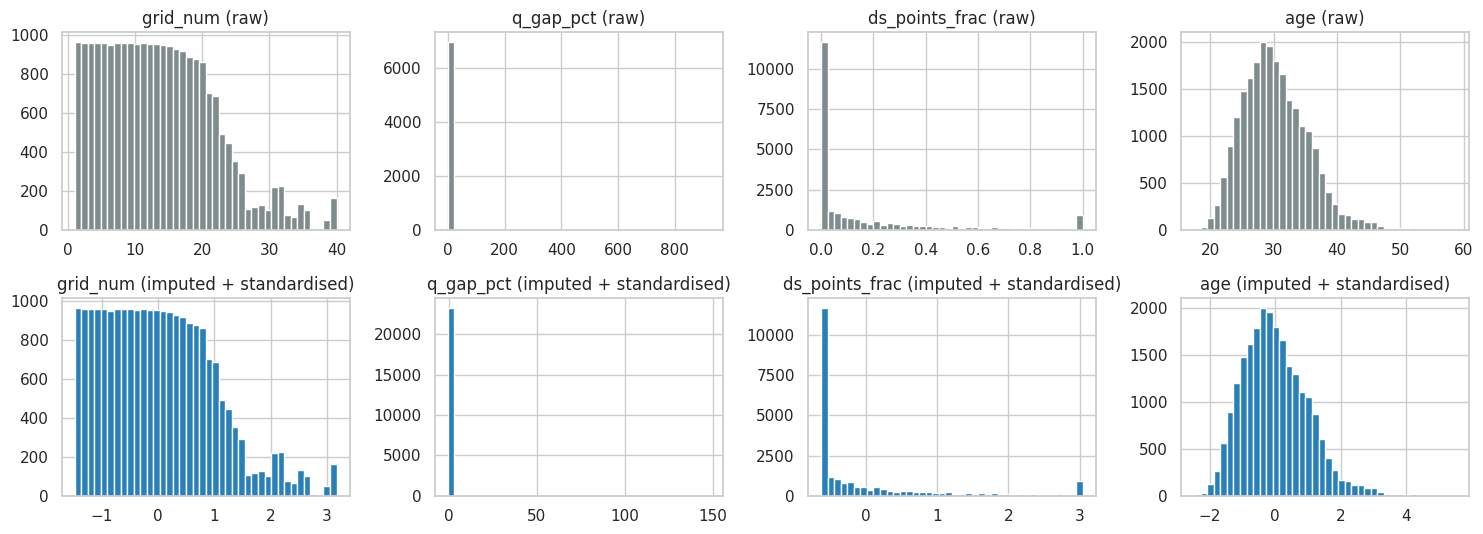

,raw_min,raw_max,raw_missing,scaled_mean,scaled_std,scaled_missing
grid_num,1.000,40.000,0,0.0,1.0,0
q_gap_pct,0.000,922.862,16287,0.0,1.0,0
ds_points_frac,0.000,1.000,0,-0.0,1.0,0
age,17.454,58.787,0,0.0,1.0,0


In [148]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

show_cols = ["grid_num", "q_gap_pct", "ds_points_frac", "age"]
imp = SimpleImputer(strategy="median", keep_empty_features=True).fit(X_train)
sc = StandardScaler().fit(imp.transform(X_train))
Z = pd.DataFrame(sc.transform(imp.transform(X_train)), columns=FEATURES, index=X_train.index)

fig, axes = plt.subplots(2, len(show_cols), figsize=(15, 5.5))
for j, c in enumerate(show_cols):
    axes[0, j].hist(X_train[c].dropna(), bins=40, color="#7f8c8d"); axes[0, j].set_title(f"{c} (raw)")
    axes[1, j].hist(Z[c], bins=40, color="#2980b9"); axes[1, j].set_title(f"{c} (imputed + standardised)")
plt.tight_layout(); plt.show()

eff = pd.DataFrame({"raw_min": X_train[show_cols].min(), "raw_max": X_train[show_cols].max(),
                    "raw_missing": X_train[show_cols].isna().sum(),
                    "scaled_mean": Z[show_cols].mean(), "scaled_std": Z[show_cols].std(),
                    "scaled_missing": Z[show_cols].isna().sum()})
display(eff.round(3))

## 9. Predictive modeling

**Models (all trained on the same rows and the same feature set):**
1. **Logistic regression (baseline).** Learns a weighted sum of the features and squeezes it through a sigmoid to get a probability. Simple, fast and easy to interpret. *Limits:* it can only draw a straight decision boundary, so interactions (a good driver in a weak car) must be present in the features.
2. **Gradient boosting (`HistGradientBoostingClassifier`).** Builds many small decision trees in sequence, each correcting the errors of the previous ones. Captures non-linear effects and interactions and handles missing values natively. *Limits:* more hyperparameters, can overfit, harder to explain.
3. **Random forest.** Averages many deep trees trained on random subsets of rows and features. *Limits:* probabilities are less well calibrated and the model is large.
4. **Shallow neural network (`MLPClassifier`, 1-2 hidden layers).** Layers of weighted sums with non-linear activations, trained by gradient descent with L2 regularisation. *Limits:* needs scaled and imputed inputs and is sensitive to initialisation; on small tabular data it rarely beats boosted trees.

**Reference points, not models:** a rule "podium if grid <= 3" and a logistic regression using the grid position only.

**Selection protocol.** Hyperparameters are chosen on the **validation** set by PR-AUC. The decision threshold for F1 / precision / recall is the one that maximises F1 on the **validation** set. The test set is only used for the final report.

**Metrics.** *Primary: PR-AUC* (average precision). Podiums are rare (about 1 row in 8), and PR-AUC measures how well the model ranks the few true podium finishers at the top, which is the real use case. *Secondary: ROC-AUC* (overall separation, less sensitive to the class ratio). We also report F1, precision and recall at the validation-chosen threshold. Accuracy is not reported as a headline because predicting "no podium" for everyone already scores about 87%.

,family,config,val_PR-AUC,val_ROC-AUC
7,Gradient Boosting,"lr=0.03, depth=5, l2=1.0",0.7084,0.9424
5,Gradient Boosting,"lr=0.03, depth=3, l2=1.0",0.7020,0.9432
4,Gradient Boosting,"lr=0.03, depth=3, l2=0.0",0.7016,0.9430
6,Gradient Boosting,"lr=0.03, depth=5, l2=0.0",0.6966,0.9410
9,Gradient Boosting,"lr=0.1, depth=3, l2=1.0",0.6903,0.9405
11,Gradient Boosting,"lr=0.1, depth=5, l2=1.0",0.6850,0.9380
10,Gradient Boosting,"lr=0.1, depth=5, l2=0.0",0.6842,0.9350
8,Gradient Boosting,"lr=0.1, depth=3, l2=0.0",0.6763,0.9380
3,Logistic Regression,C=10,0.7061,0.9361
2,Logistic Regression,C=1,0.7059,0.9361


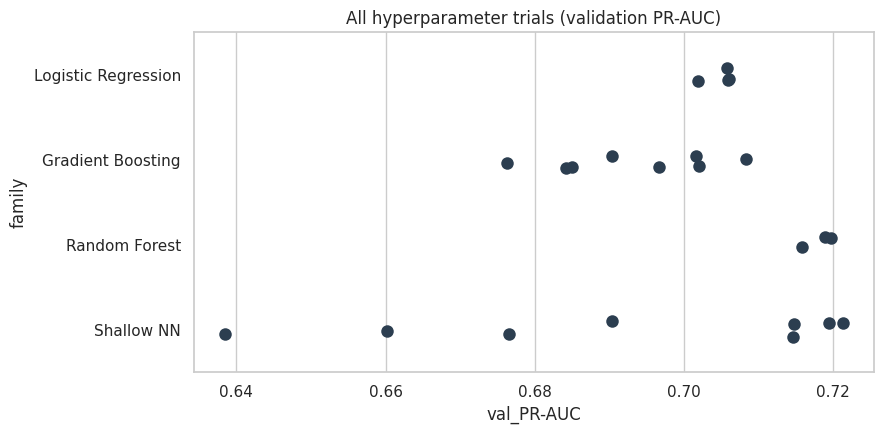

In [149]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (average_precision_score, f1_score, precision_score, recall_score,
                             precision_recall_curve, roc_curve, confusion_matrix)

def _pre(scale):
    steps = [("imp", SimpleImputer(strategy="median", keep_empty_features=True))]
    if scale:
        steps.append(("sc", StandardScaler()))
    return steps

def make_lr(C=1.0):      return Pipeline(_pre(True) + [("clf", LogisticRegression(C=C, max_iter=3000, random_state=SEED))])
def make_hgb(**p):       return Pipeline([("clf", HistGradientBoostingClassifier(max_iter=200, early_stopping=False, random_state=SEED, **p))])
def make_rf(**p):        return Pipeline(_pre(False) + [("clf", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, **p))])
def make_mlp(h, alpha):  return Pipeline(_pre(True) + [("clf", MLPClassifier(hidden_layer_sizes=h, alpha=alpha, max_iter=150,
                                                                           n_iter_no_change=10, random_state=SEED))])

def best_threshold(yv, p):
    pr, rc, th = precision_recall_curve(yv, p)
    f1 = 2 * pr * rc / (pr + rc + 1e-12)
    return float(th[np.nanargmax(f1[:-1])])

def metrics_at(yv, p, thr):
    yhat = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(yv, p), "PR-AUC": average_precision_score(yv, p),
            "F1": f1_score(yv, yhat, zero_division=0), "Precision": precision_score(yv, yhat, zero_division=0),
            "Recall": recall_score(yv, yhat, zero_division=0)}

# ---- hyperparameter trials: every attempt is recorded and judged on VALIDATION only -------------
trials, trial_models = [], {}
def run_trial(family, label, factory, feats=FEATURES):
    m = factory(); m.fit(X_train[feats], y_train)
    pv = m.predict_proba(X_val[feats])[:, 1]
    trials.append({"family": family, "config": label, "val_PR-AUC": average_precision_score(y_val, pv),
                   "val_ROC-AUC": roc_auc_score(y_val, pv)})
    trial_models[(family, label)] = (m, factory)

for c_reg in [0.01, 0.1, 1, 10]:   # not named C: a global C would shadow patsy's C() used in Q2 on a re-run
    run_trial("Logistic Regression", f"C={c_reg}", lambda c_reg=c_reg: make_lr(c_reg))
for lr in [0.03, 0.1]:
    for depth in [3, 5]:
        for l2 in [0.0, 1.0]:
            run_trial("Gradient Boosting", f"lr={lr}, depth={depth}, l2={l2}",
                      lambda lr=lr, depth=depth, l2=l2: make_hgb(learning_rate=lr, max_depth=depth, l2_regularization=l2))
for leaf, depth in [(5, None), (20, None), (20, 10)]:
    run_trial("Random Forest", f"min_leaf={leaf}, depth={depth}",
              lambda leaf=leaf, depth=depth: make_rf(min_samples_leaf=leaf, max_depth=depth))
for h in [(16,), (32,), (64, 32), (32, 16)]:
    for alpha in [1e-4, 1e-2]:
        run_trial("Shallow NN", f"hidden={h}, alpha={alpha}", lambda h=h, alpha=alpha: make_mlp(h, alpha))

trial_df = pd.DataFrame(trials)
display(trial_df.sort_values(["family", "val_PR-AUC"], ascending=[True, False]).round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.stripplot(data=trial_df, x="val_PR-AUC", y="family", size=9, ax=ax, color="#2c3e50")
ax.set_title("All hyperparameter trials (validation PR-AUC)"); plt.tight_layout(); plt.show()

In [150]:
# Best configuration per family (by validation PR-AUC) -> the final model of that family
FAMILIES = ["Logistic Regression", "Gradient Boosting", "Random Forest", "Shallow NN"]
BEST = {}
for fam in FAMILIES:
    t = trial_df[trial_df.family == fam].sort_values("val_PR-AUC", ascending=False).iloc[0]
    BEST[fam] = {"config": t["config"], "model": trial_models[(fam, t["config"])][0], "factory": trial_models[(fam, t["config"])][1]}
    print(f"{fam:22s} -> {t['config']}   (val PR-AUC {t['val_PR-AUC']:.4f})")

# Reference points
grid_feats = GROUPS["grid"]
lr_grid = make_lr(1.0).fit(X_train[grid_feats], y_train)

def score_model(name):
    if name == "Rule: grid <= 3":
        return lambda X: 1.0 / X["grid_num"].values, 1.0 / 3
    if name == "LR (grid only)":
        return lambda X: lr_grid.predict_proba(X[grid_feats])[:, 1], None
    m = BEST[name]["model"]
    return lambda X: m.predict_proba(X[FEATURES])[:, 1], None

MODEL_NAMES = ["Rule: grid <= 3", "LR (grid only)"] + FAMILIES
SPLITS = {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}
THR, PROBS, rows = {}, {}, []
for name in MODEL_NAMES:
    f, fixed_thr = score_model(name)
    PROBS[name] = {s: f(X) for s, (X, _) in SPLITS.items()}
    THR[name] = fixed_thr if fixed_thr is not None else best_threshold(y_val, PROBS[name]["val"])   # threshold from VALIDATION only
    for s, (X, yv) in SPLITS.items():
        rows.append({"model": name, "split": s, **metrics_at(yv, PROBS[name][s], THR[name])})
results_long = pd.DataFrame(rows)

cmp_full = results_long.pivot(index="model", columns="split", values=["PR-AUC", "ROC-AUC", "F1", "Precision", "Recall"]) \
                        .reindex(MODEL_NAMES)
cmp_full = cmp_full.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
cmp_full = cmp_full[[(s, m) for s in ["train", "val", "test"] for m in ["PR-AUC", "ROC-AUC", "F1", "Precision", "Recall"]]]
print("MODEL COMPARISON (threshold chosen on validation; Rule uses grid<=3):")
display(cmp_full.round(4))
print("Chosen thresholds:", {k: round(v, 3) for k, v in THR.items()})

Logistic Regression    -> C=10   (val PR-AUC 0.7061)
Gradient Boosting      -> lr=0.03, depth=5, l2=1.0   (val PR-AUC 0.7084)
Random Forest          -> min_leaf=20, depth=10   (val PR-AUC 0.7197)
Shallow NN             -> hidden=(32,), alpha=0.01   (val PR-AUC 0.7213)
MODEL COMPARISON (threshold chosen on validation; Rule uses grid<=3):


split                 train                                       val                                      test                                  
                     PR-AUC ROC-AUC      F1 Precision  Recall  PR-AUC ROC-AUC      F1 Precision  Recall  PR-AUC ROC-AUC      F1 Precision  Recall
model                                                                                                                                            
Rule: grid <= 3      0.4800  0.8878  0.5286    0.5278  0.5294  0.6851  0.9256  0.7146    0.7161  0.7131  0.6460  0.9114  0.6605    0.6617  0.6593
LR (grid only)       0.4800  0.8879  0.5286    0.5278  0.5294  0.6851  0.9256  0.7146    0.7161  0.7131  0.6460  0.9114  0.6605    0.6617  0.6593
Logistic Regression  0.5622  0.9037  0.5593    0.5432  0.5765  0.7061  0.9361  0.7209    0.6414  0.8228  0.7210  0.9354  0.6781    0.6306  0.7333
Gradient Boosting    0.6416  0.9289  0.5809    0.6150  0.5503  0.7084  0.9424  0.7287    0.7004  0.7595  0.7035  0.9353  0.6590    0.6825  0.6370
Random Forest        0.6599  0.9306  0.5926    0.6516  0.5434  0.7197  0.9437  0.7157    0.6767  0.7595  0.7219  0.9397  0.6778    0.6778  0.6778
Shallow NN           0.6024  0.9151  0.5530    0.5998  0.5131  0.7213  0.9426  0.7239    0.7024  0.7468  0.6885  0.9304  0.6306    0.6599  0.6037

Chosen thresholds: {'Rule: grid <= 3': 0.333, 'LR (grid only)': 0.422, 'Logistic Regression': 0.354, 'Gradient Boosting': 0.43, 'Random Forest': 0.423, 'Shallow NN': 0.435}


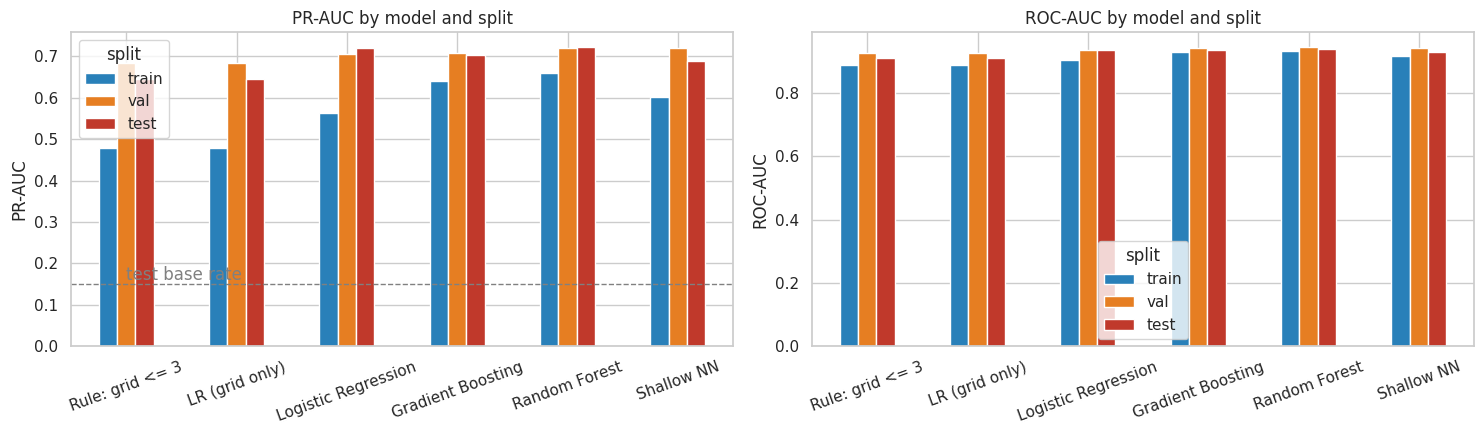

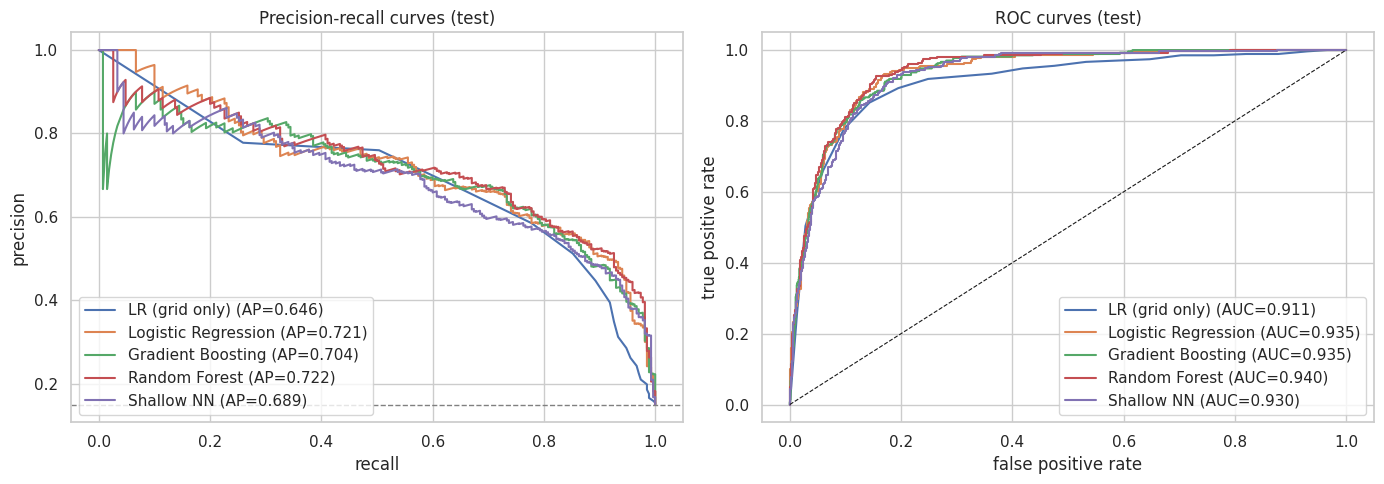

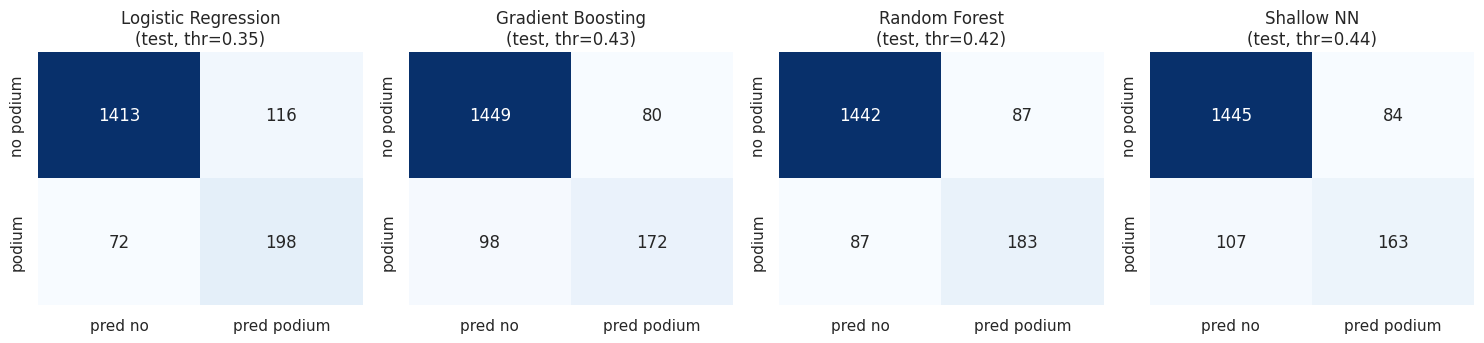

Ranking by validation PR-AUC (primary metric):


,PR-AUC
model,
Shallow NN,0.7213
Random Forest,0.7197
Gradient Boosting,0.7084
Logistic Regression,0.7061


Best family by validation PR-AUC: Shallow NN (hidden=(32,), alpha=0.01)
Is the more complex model worth it? Baseline LR val PR-AUC = 0.7061 vs Shallow NN = 0.7213  (gain +0.0152).


In [151]:
# Plots of the comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, metric in zip(axes, ["PR-AUC", "ROC-AUC"]):
    d = results_long.pivot(index="model", columns="split", values=metric).reindex(MODEL_NAMES)[["train", "val", "test"]]
    d.plot.bar(ax=ax, color=[colors["train"], colors["val"], colors["test"]], rot=20)
    ax.set_title(f"{metric} by model and split"); ax.set_ylabel(metric); ax.set_xlabel("")
    if metric == "PR-AUC":
        ax.axhline(y_test.mean(), color="grey", ls="--", lw=1); ax.text(0, y_test.mean() + 0.01, "test base rate", color="grey")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in MODEL_NAMES[1:]:
    p = PROBS[name]["test"]
    pr, rc, _ = precision_recall_curve(y_test, p); fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
axes[0].axhline(y_test.mean(), color="grey", ls="--", lw=1)
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_title("Precision-recall curves (test)"); axes[0].legend()
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].set_title("ROC curves (test)"); axes[1].legend(); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(FAMILIES), figsize=(15, 3.6))
for ax, name in zip(axes, FAMILIES):
    cm = confusion_matrix(y_test, (PROBS[name]["test"] >= THR[name]).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred no", "pred podium"], yticklabels=["no podium", "podium"])
    ax.set_title(f"{name}\n(test, thr={THR[name]:.2f})")
plt.tight_layout(); plt.show()

PRIMARY = "PR-AUC"
val_rank = results_long[results_long.split == "val"].set_index("model").loc[FAMILIES, PRIMARY].sort_values(ascending=False)
BEST_NAME = val_rank.index[0]
print("Ranking by validation PR-AUC (primary metric):")
display(val_rank.round(4).to_frame())
print(f"Best family by validation PR-AUC: {BEST_NAME} ({BEST[BEST_NAME]['config']})")
print(f"Is the more complex model worth it? Baseline LR val PR-AUC = {val_rank['Logistic Regression']:.4f} vs "
      f"{BEST_NAME} = {val_rank.iloc[0]:.4f}  (gain {val_rank.iloc[0] - val_rank['Logistic Regression']:+.4f}).")

**Reading the comparison.**
- *Baselines:* the rule "grid <= 3" and the grid-only logistic regression give identical results (test PR-AUC 0.646, F1 0.661), so one feature already captures most of the signal.
- *Added features:* the four feature models raise test PR-AUC to 0.689-0.722 and ROC-AUC to 0.930-0.940. Thresholded F1 improves much less (0.631-0.678), and the neural network is below the rule baseline on test F1.
- *Train vs validation vs test:* train scores are lower than validation and test for every model. This is not overfitting. The train block includes early eras with long grids and no qualifying data, which are harder to rank. The real overfitting signal is the validation-to-test drop: shallow NN -0.033 PR-AUC, gradient boosting -0.005, while logistic regression and random forest are stable or slightly better.
- *Model choice:* the shallow NN has the best validation PR-AUC (0.7213) and is used as the final model by our pre-declared rule. On test it is the weakest of the four feature models. Logistic regression (0.7210) and random forest (0.7219) are within 0.001 of the best test score, and logistic regression is the simplest, so added complexity did not pay off here.
- *Noise:* validation has only 237 podiums and test has 270, so differences of 0.01-0.02 PR-AUC between models are within noise.


## 10. Experiments

### 10.1 Feature-set build-up (trial record)
Starting from the grid alone, one feature group is added at a time with the best gradient-boosting settings. This is the empirical before/after record behind the final feature set.

,n_features,val_PR-AUC,val_ROC-AUC,val_F1,test_PR-AUC,test_ROC-AUC,test_F1
feature set,,,,,,,
grid,2,0.6852,0.9263,0.7146,0.6459,0.9106,0.6605
+ qualifying,6,0.7124,0.9323,0.7101,0.6544,0.9237,0.6678
+ driver_form,10,0.7247,0.9417,0.7224,0.6960,0.9306,0.6562
+ team_form,12,0.7272,0.9429,0.7276,0.6877,0.9324,0.6527
+ standings,18,0.7042,0.9414,0.7302,0.6990,0.9342,0.6511
+ context,22,0.7084,0.9424,0.7287,0.7035,0.9353,0.6590


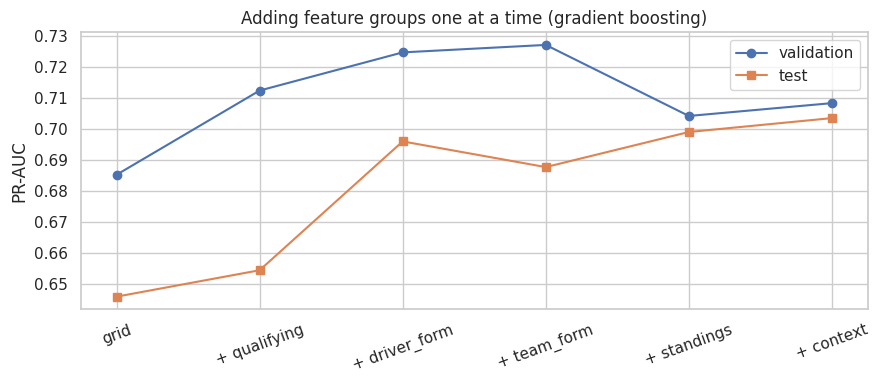

In [152]:
HGB_F, LR_F = BEST["Gradient Boosting"]["factory"], BEST["Logistic Regression"]["factory"]

def eval_feats(factory, feats):
    m = factory(); m.fit(X_train[feats], y_train)
    pv, pt = m.predict_proba(X_val[feats])[:, 1], m.predict_proba(X_test[feats])[:, 1]
    thr = best_threshold(y_val, pv)
    return {"n_features": len(feats), "val_PR-AUC": average_precision_score(y_val, pv), "val_ROC-AUC": roc_auc_score(y_val, pv),
            "val_F1": f1_score(y_val, pv >= thr), "test_PR-AUC": average_precision_score(y_test, pt),
            "test_ROC-AUC": roc_auc_score(y_test, pt), "test_F1": f1_score(y_test, pt >= thr)}

steps, acc, build = [], [], []
for g in GROUPS:
    acc = acc + GROUPS[g]
    label = "grid" if g == "grid" else f"+ {g}"
    build.append({"feature set": label, **eval_feats(HGB_F, list(acc))})
build_df = pd.DataFrame(build).set_index("feature set")
display(build_df.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(build_df.index, build_df["val_PR-AUC"], marker="o", label="validation")
ax.plot(build_df.index, build_df["test_PR-AUC"], marker="s", label="test")
ax.set_ylabel("PR-AUC"); ax.set_title("Adding feature groups one at a time (gradient boosting)"); ax.legend()
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

### 10.2 Feature-group ablation (leave one group out)
Each group is removed in turn, the model is retrained with the same hyperparameters, and the drop in performance against the full model is reported. A small drop does not mean the group is useless: correlated groups (for example grid and qualifying) can substitute for each other.

,model,removed group,n_features,val_PR-AUC,val_ROC-AUC,val_F1,test_PR-AUC,test_ROC-AUC,test_F1,d_val_PR-AUC,d_test_PR-AUC
0,Gradient Boosting,none (full model),22,0.7084,0.9424,0.7287,0.7035,0.9353,0.6590,0.0000,0.0000
1,Gradient Boosting,grid,20,0.7067,0.9429,0.7099,0.7033,0.9311,0.6540,-0.0016,-0.0003
2,Gradient Boosting,qualifying,18,0.6912,0.9411,0.7294,0.7107,0.9320,0.6615,-0.0172,0.0071
3,Gradient Boosting,driver_form,18,0.7093,0.9428,0.7195,0.7167,0.9401,0.6782,0.0010,0.0132
4,Gradient Boosting,team_form,20,0.6973,0.9410,0.7183,0.7098,0.9369,0.6791,-0.0110,0.0062
5,Gradient Boosting,standings,16,0.7311,0.9431,0.7276,0.7022,0.9353,0.6641,0.0228,-0.0013
6,Gradient Boosting,context,18,0.7042,0.9414,0.7302,0.6990,0.9342,0.6511,-0.0041,-0.0045
7,Logistic Regression,none (full model),22,0.7061,0.9361,0.7209,0.7210,0.9354,0.6781,0.0000,0.0000
8,Logistic Regression,grid,20,0.6936,0.9375,0.7158,0.7027,0.9324,0.6568,-0.0125,-0.0183
9,Logistic Regression,qualifying,18,0.7082,0.9370,0.7193,0.7140,0.9325,0.6815,0.0021,-0.0070


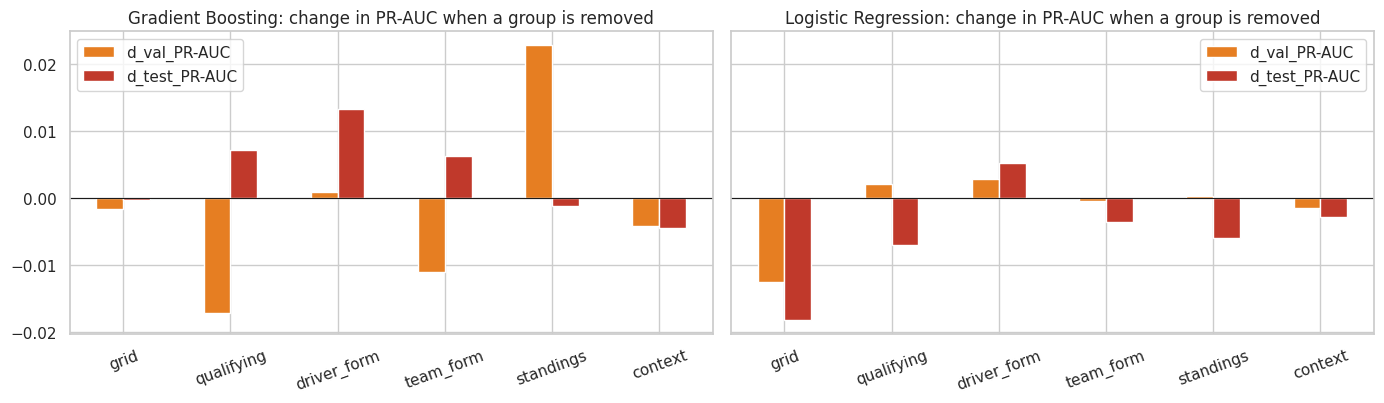

In [153]:
abl = []
for mname, fac in [("Gradient Boosting", HGB_F), ("Logistic Regression", LR_F)]:
    full = eval_feats(fac, FEATURES)
    abl.append({"model": mname, "removed group": "none (full model)", **full, "d_val_PR-AUC": 0.0, "d_test_PR-AUC": 0.0})
    for g in GROUPS:
        feats = [c for c in FEATURES if c not in GROUPS[g]]
        r = eval_feats(fac, feats)
        abl.append({"model": mname, "removed group": g, **r,
                    "d_val_PR-AUC": r["val_PR-AUC"] - full["val_PR-AUC"], "d_test_PR-AUC": r["test_PR-AUC"] - full["test_PR-AUC"]})
ablation = pd.DataFrame(abl)
display(ablation.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, mname in zip(axes, ["Gradient Boosting", "Logistic Regression"]):
    d = ablation[(ablation.model == mname) & (ablation["removed group"] != "none (full model)")].set_index("removed group")
    d[["d_val_PR-AUC", "d_test_PR-AUC"]].plot.bar(ax=ax, rot=20, color=[colors["val"], colors["test"]])
    ax.axhline(0, color="k", lw=0.8); ax.set_title(f"{mname}: change in PR-AUC when a group is removed"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

### 10.3 Preprocessing-order experiments (logistic regression)
Logistic regression is scale-sensitive, so preprocessing choices matter most for it. Three order questions, each answered with the same model and the same rows:
- **A. Impute then scale** vs **scale then impute** (with a NaN-aware scaler).
- **B. Fit the preprocessing statistics on the training rows only** (correct) vs **on all rows including validation and test** (leaky; shown only to measure how much leakage would inflate the score).
- **C. Winsorise (clip to the 1st-99th training percentile) before scaling** vs **scale first and then clip at +/-3 standard deviations**.

,val_PR-AUC,val_ROC-AUC,test_PR-AUC,test_ROC-AUC
experiment,,,,
A1 impute -> scale (train stats),0.7061,0.9361,0.7210,0.9354
A2 scale -> impute (train stats),0.7063,0.9360,0.7208,0.9355
B1 fit on TRAIN only (correct),0.7061,0.9361,0.7210,0.9354
B2 fit on ALL rows (leaky),0.7064,0.9361,0.7208,0.9353
C1 winsorise -> scale,0.7049,0.9365,0.7236,0.9358
C2 scale -> clip at +/-3 sd,0.7063,0.9368,0.7226,0.9353


A: validation PR-AUC difference (A2 minus A1) = +0.0002
B: validation PR-AUC difference (B2 minus B1) = +0.0003
C: validation PR-AUC difference (C2 minus C1) = +0.0014


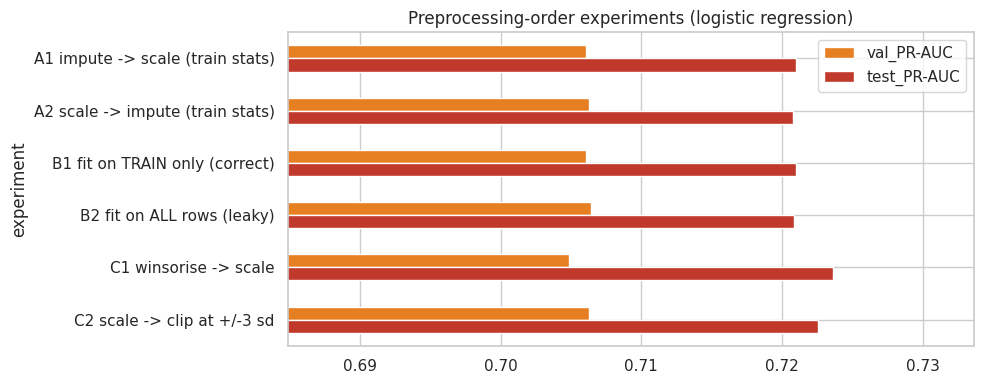

In [154]:
Cbest = float(BEST["Logistic Regression"]["config"].split("=")[1])
ALL = pd.concat([X_train, X_val, X_test])

def fit_eval_arrays(Atr, Ava, Ate):
    m = LogisticRegression(C=Cbest, max_iter=3000, random_state=SEED).fit(Atr, y_train)
    pv, pt = m.predict_proba(Ava)[:, 1], m.predict_proba(Ate)[:, 1]
    return {"val_PR-AUC": average_precision_score(y_val, pv), "val_ROC-AUC": roc_auc_score(y_val, pv),
            "test_PR-AUC": average_precision_score(y_test, pt), "test_ROC-AUC": roc_auc_score(y_test, pt)}

def impute_then_scale(fit_df):
    med = fit_df.median(); sc_ = StandardScaler().fit(fit_df.fillna(med))
    return [sc_.transform(d.fillna(med)) for d in (X_train, X_val, X_test)]

def scale_then_impute(fit_df):
    sc_ = StandardScaler().fit(fit_df)                    # NaN-aware: ignores missing values when fitting
    scaled = lambda d: pd.DataFrame(sc_.transform(d), columns=FEATURES, index=d.index)
    med = scaled(fit_df).median()
    return [scaled(d).fillna(med).values for d in (X_train, X_val, X_test)]

def winsor_then_scale(fit_df):
    lo, hi = fit_df.quantile(0.01), fit_df.quantile(0.99)
    clip = lambda d: d.clip(lo, hi, axis=1)
    cf = clip(fit_df); med = cf.median(); sc_ = StandardScaler().fit(cf.fillna(med))
    return [sc_.transform(clip(d).fillna(med)) for d in (X_train, X_val, X_test)]

def scale_then_clip(fit_df):
    A = impute_then_scale(fit_df)
    return [np.clip(a, -3, 3) for a in A]

exps = [("A1 impute -> scale (train stats)", impute_then_scale(X_train)),
        ("A2 scale -> impute (train stats)", scale_then_impute(X_train)),
        ("B1 fit on TRAIN only (correct)",   impute_then_scale(X_train)),
        ("B2 fit on ALL rows (leaky)",       impute_then_scale(ALL)),
        ("C1 winsorise -> scale",            winsor_then_scale(X_train)),
        ("C2 scale -> clip at +/-3 sd",      scale_then_clip(X_train))]
pre_rows = [{"experiment": n, **fit_eval_arrays(*A)} for n, A in exps]
pre_df = pd.DataFrame(pre_rows).set_index("experiment")
display(pre_df.round(4))

for a, b in [("A1 impute -> scale (train stats)", "A2 scale -> impute (train stats)"),
             ("B1 fit on TRAIN only (correct)", "B2 fit on ALL rows (leaky)"),
             ("C1 winsorise -> scale", "C2 scale -> clip at +/-3 sd")]:
    d = pre_df.loc[b, "val_PR-AUC"] - pre_df.loc[a, "val_PR-AUC"]
    print(f"{a[0]}: validation PR-AUC difference ({b[:2]} minus {a[:2]}) = {d:+.4f}")

fig, ax = plt.subplots(figsize=(10, 4))
pre_df[["val_PR-AUC", "test_PR-AUC"]].plot.barh(ax=ax, color=[colors["val"], colors["test"]])
lo = pre_df[["val_PR-AUC", "test_PR-AUC"]].min().min()
ax.set_xlim(lo - 0.02, pre_df[["val_PR-AUC", "test_PR-AUC"]].max().max() + 0.01); ax.invert_yaxis()
ax.set_title("Preprocessing-order experiments (logistic regression)"); plt.tight_layout(); plt.show()

**Reading it:** differences between the orderings are small because median imputation and standardisation commute almost exactly for a handful of missing values. The point of B is the *principle*: statistics computed on rows from the future (validation/test) are information the model could not have had, so every preprocessing step is fitted on the training rows only in the final pipeline. Fitting on all rows changes numbers only slightly here, but it would be a leak in a real deployment.

### 10.4 Training-window experiment (era sensitivity)
Qualifying times only exist from 1994 and the sport has changed a lot. Does training only on more modern seasons help on the (modern) validation set? This is a *comparison*, not the main model, because the main models use the same training rows.

In [155]:
tw = []
for start in [1950, 1980, 1994, 2006]:
    m = BEST["Gradient Boosting"]["factory"](); mask = (fe.loc[fe.split == "train", "year"] >= start).values
    m.fit(X_train[mask], y_train[mask])
    pv, pt = m.predict_proba(X_val)[:, 1], m.predict_proba(X_test)[:, 1]
    tw.append({"train from": start, "train rows": int(mask.sum()), "val_PR-AUC": average_precision_score(y_val, pv),
               "val_ROC-AUC": roc_auc_score(y_val, pv), "test_PR-AUC": average_precision_score(y_test, pt),
               "test_ROC-AUC": roc_auc_score(y_test, pt)})
window_df = pd.DataFrame(tw).set_index("train from")
display(window_df.round(4))

,train rows,val_PR-AUC,val_ROC-AUC,test_PR-AUC,test_ROC-AUC
train from,,,,,
1950,23289,0.7084,0.9424,0.7035,0.9353
1980,15453,0.7029,0.9423,0.6971,0.9355
1994,8979,0.7047,0.9421,0.7020,0.9313
2006,4535,0.7281,0.9432,0.6739,0.9274


## 11. Model explainability (XAI)

We explain the model with the best validation PR-AUC. Remember: **these explanations describe what the model relies on to make predictions, not what causes podium finishes.** A feature can be important because it is correlated with something real (a fast car) without being a cause itself, and correlated features share importance.

Global: permutation importance (computed on the validation set, scored by PR-AUC) and SHAP (mean absolute contribution). Local: SHAP waterfall and LIME for single predictions.

Explaining: Shallow NN | hidden=(32,), alpha=0.01


,feature,mean_drop,std,group
0,grid_num,0.0943,0.0108,grid
1,q_pos,0.0498,0.0104,qualifying
2,drv_podiums_career,0.0417,0.0207,driver_form
3,round,0.0303,0.0081,context
4,grid_vs_quali,0.0188,0.0073,qualifying
5,con_podium_rate,0.0142,0.0070,team_form
6,ds_wins,0.0139,0.0032,standings
7,drv_podium_rate,0.0138,0.0039,driver_form
8,drv_finish_frac,0.0129,0.0030,driver_form
9,cs_points_frac,0.0114,0.0025,standings


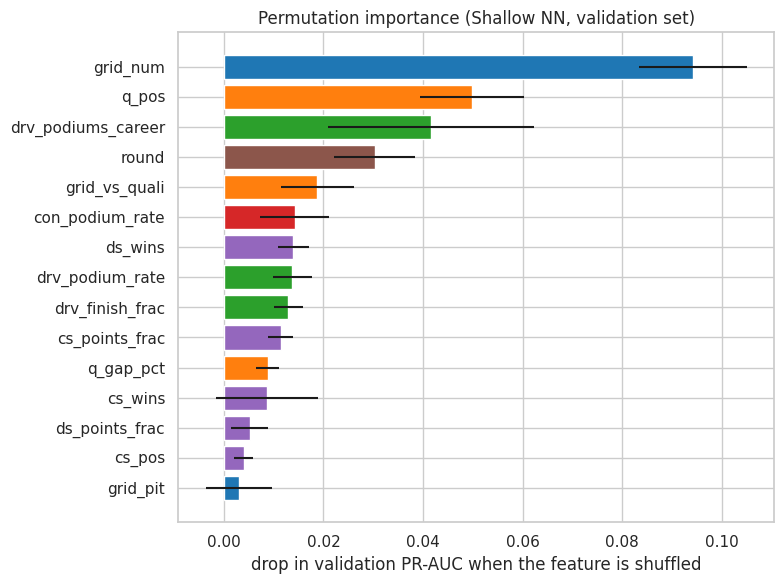

Permutation importance summed by feature group (groups with correlated members can look weaker individually):


,sum of drops
group,
grid,0.0973
qualifying,0.0789
driver_form,0.0684
standings,0.0413
context,0.0331
team_form,0.0167


In [156]:
import sys, subprocess
def ensure(pkg, mod):
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        __import__(mod)

from sklearn.inspection import permutation_importance
XAI_NAME = BEST_NAME
XAI_MODEL = BEST[XAI_NAME]["model"]
print("Explaining:", XAI_NAME, "|", BEST[XAI_NAME]["config"])

pi = permutation_importance(XAI_MODEL, X_val, y_val, scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=1)
perm = pd.DataFrame({"feature": FEATURES, "mean_drop": pi.importances_mean, "std": pi.importances_std}) \
         .sort_values("mean_drop", ascending=False).reset_index(drop=True)
perm["group"] = perm["feature"].map({c: g for g, cols in GROUPS.items() for c in cols})
display(perm.head(15).round(4))

fig, ax = plt.subplots(figsize=(8, 6))
t = perm.head(15).iloc[::-1]
ax.barh(t["feature"], t["mean_drop"], xerr=t["std"], color=[pal[g] for g in t["group"]])
ax.set_xlabel("drop in validation PR-AUC when the feature is shuffled")
ax.set_title(f"Permutation importance ({XAI_NAME}, validation set)")
plt.tight_layout(); plt.show()

gperm = perm.groupby("group")["mean_drop"].sum().sort_values(ascending=False)
print("Permutation importance summed by feature group (groups with correlated members can look weaker individually):")
display(gperm.round(4).to_frame("sum of drops"))

PermutationExplainer explainer: 201it [00:17,  5.12it/s]                         


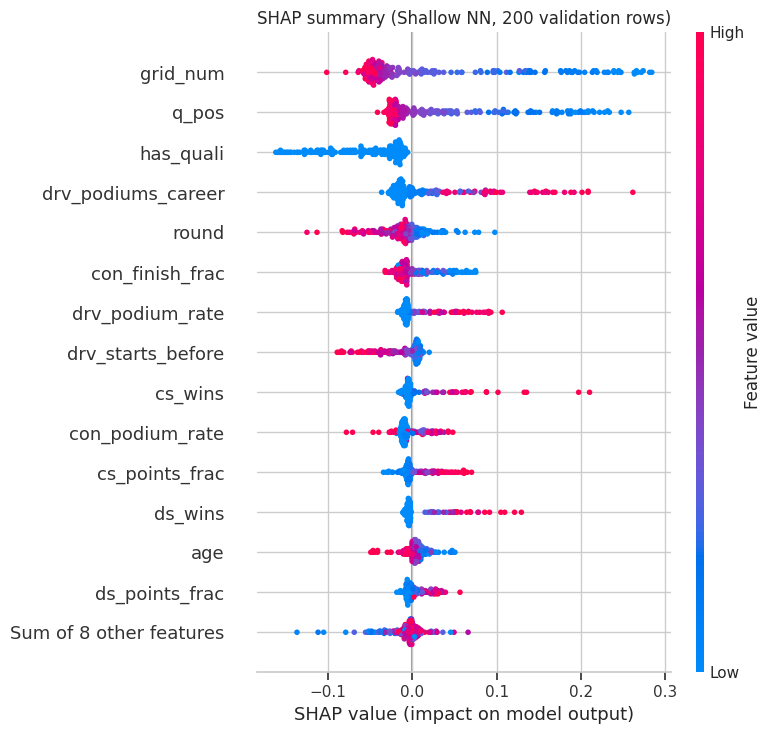

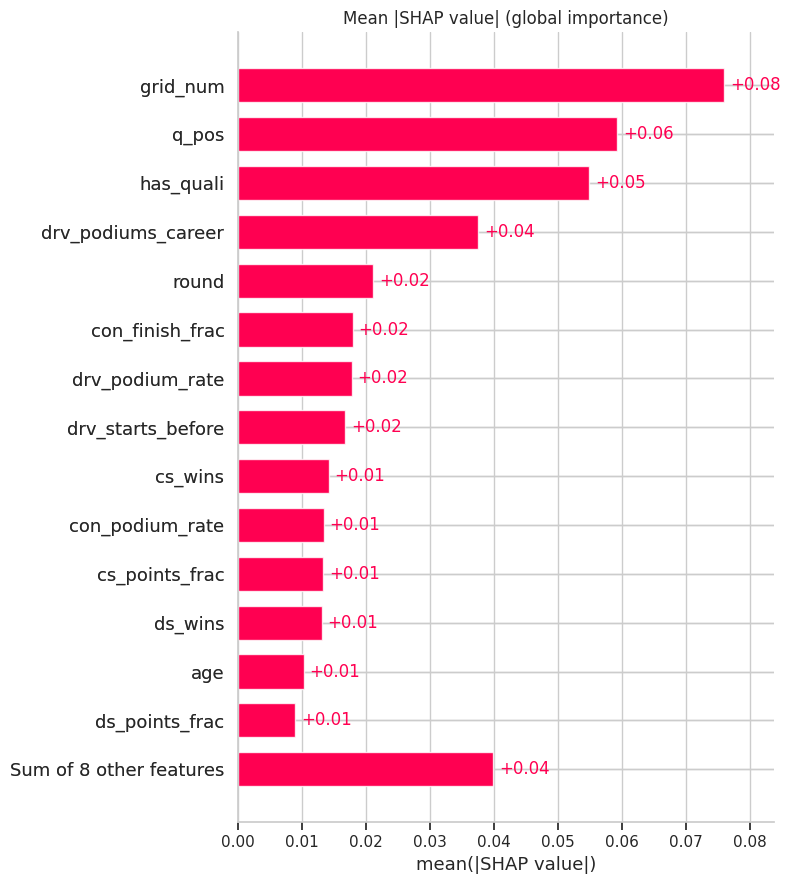

,mean |SHAP|
grid_num,0.0760
q_pos,0.0593
has_quali,0.0549
drv_podiums_career,0.0376
round,0.0212
con_finish_frac,0.0180
drv_podium_rate,0.0179
drv_starts_before,0.0168
cs_wins,0.0142
con_podium_rate,0.0135


In [157]:
SHAP_OK = False
try:
    ensure("shap", "shap")
    import shap
    def f_proba(d):
        return XAI_MODEL.predict_proba(pd.DataFrame(np.asarray(d, dtype=float), columns=FEATURES))[:, 1]
    bg = X_train.sample(100, random_state=SEED)
    X_exp = X_val.sample(min(200, len(X_val)), random_state=SEED)
    explainer = shap.Explainer(f_proba, bg)
    sv = explainer(X_exp)
    SHAP_OK = True

    shap.plots.beeswarm(sv, max_display=15, show=False)
    plt.title(f"SHAP summary ({XAI_NAME}, 200 validation rows)"); plt.tight_layout(); plt.show()
    shap.plots.bar(sv, max_display=15, show=False)
    plt.title("Mean |SHAP value| (global importance)"); plt.tight_layout(); plt.show()

    shap_imp = pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False)
    display(shap_imp.head(10).round(4).to_frame("mean |SHAP|"))
except Exception as e:
    print("SHAP could not run:", type(e).__name__, e)

Example 1 (confident, correct): Verstappen, Abu Dhabi Grand Prix 2023 (Red Bull), grid 1, P(podium) = 0.98
Example 2 (podium the model missed): Gasly, São Paulo Grand Prix 2024 (Alpine F1 Team), grid 13, P(podium) = 0.00


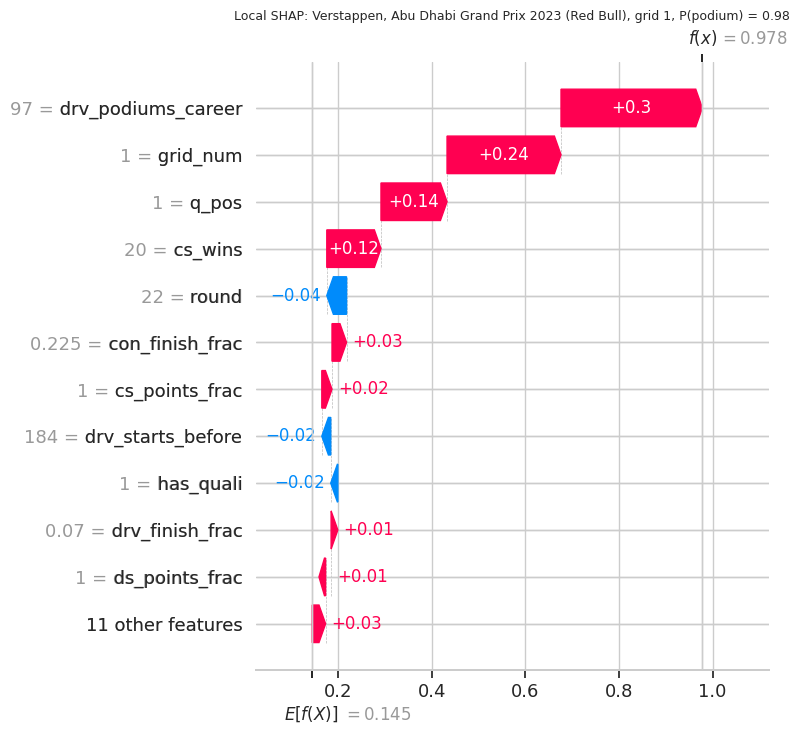

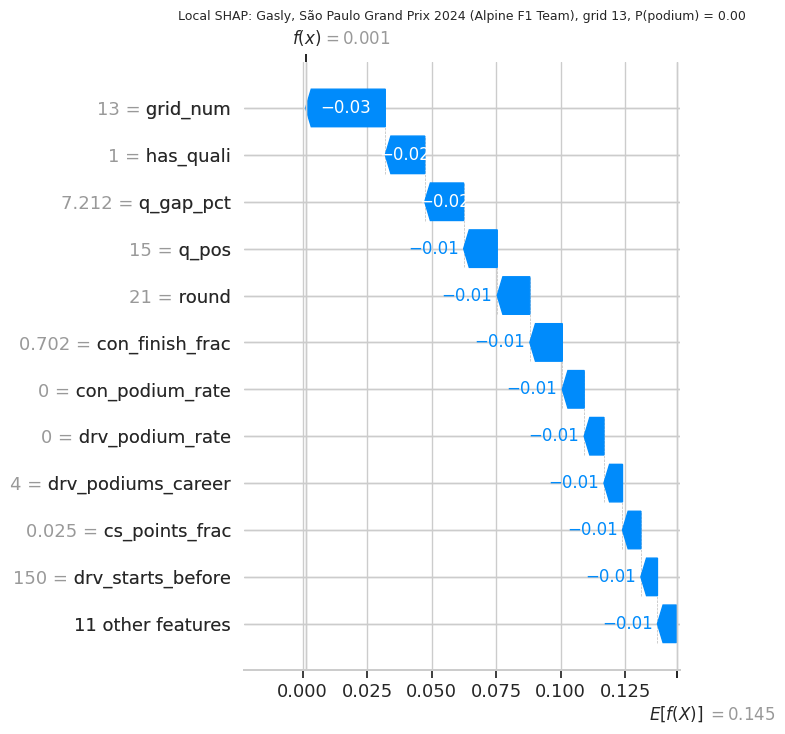

In [158]:
# Two single test predictions: the podium the model was most sure about, and the podium it missed most badly
p_test = XAI_MODEL.predict_proba(X_test)[:, 1]
pos = np.where(y_test.values == 1)[0]
i_hi, i_lo = pos[np.argmax(p_test[pos])], pos[np.argmin(p_test[pos])]
def describe(i):
    r = meta_test.iloc[i]
    return f"{r['surname']}, {r['race_name']} {int(r['year'])} ({r['constructor_name']}), grid {int(X_test.iloc[i]['grid_num'])}, P(podium) = {p_test[i]:.2f}"
print("Example 1 (confident, correct):", describe(i_hi))
print("Example 2 (podium the model missed):", describe(i_lo))

if SHAP_OK:
    sv_loc = explainer(X_test.iloc[[i_hi, i_lo]])
    for k, i in enumerate([i_hi, i_lo]):
        shap.plots.waterfall(sv_loc[k], max_display=12, show=False)
        plt.title(f"Local SHAP: {describe(i)}", fontsize=9); plt.tight_layout(); plt.show()

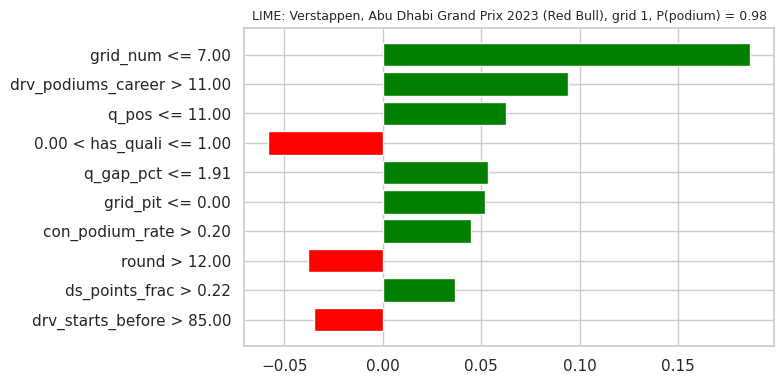

LIME weights: [('grid_num <= 7.00', 0.187), ('drv_podiums_career > 11.00', 0.094), ('q_pos <= 11.00', 0.062), ('0.00 < has_quali <= 1.00', -0.058), ('q_gap_pct <= 1.91', 0.053), ('grid_pit <= 0.00', 0.052), ('con_podium_rate > 0.20', 0.045), ('round > 12.00', -0.038), ('ds_points_frac > 0.22', 0.037), ('drv_starts_before > 85.00', -0.035)]


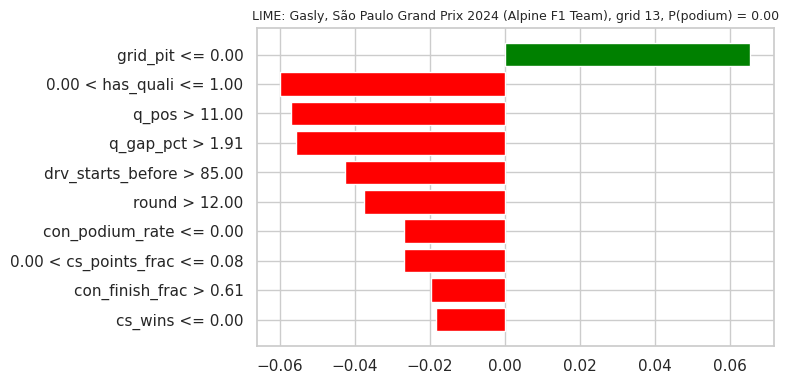

LIME weights: [('grid_pit <= 0.00', 0.065), ('0.00 < has_quali <= 1.00', -0.06), ('q_pos > 11.00', -0.057), ('q_gap_pct > 1.91', -0.056), ('drv_starts_before > 85.00', -0.043), ('round > 12.00', -0.038), ('con_podium_rate <= 0.00', -0.027), ('0.00 < cs_points_frac <= 0.08', -0.027), ('con_finish_frac > 0.61', -0.02), ('cs_wins <= 0.00', -0.018)]


In [159]:
try:
    ensure("lime", "lime")
    from lime.lime_tabular import LimeTabularExplainer
    med_tr = X_train.median()
    lime_ex = LimeTabularExplainer(X_train.fillna(med_tr).values, feature_names=FEATURES, class_names=["no podium", "podium"],
                                   mode="classification", discretize_continuous=True, random_state=SEED)
    f_lime = lambda a: XAI_MODEL.predict_proba(pd.DataFrame(a, columns=FEATURES))
    for i in [i_hi, i_lo]:
        exp = lime_ex.explain_instance(X_test.iloc[i].fillna(med_tr).values, f_lime, num_features=10, num_samples=2000)
        fig = exp.as_pyplot_figure(); fig.set_size_inches(8, 4)
        plt.title("LIME: " + describe(i), fontsize=9); plt.tight_layout(); plt.show()
        print("LIME weights:", [(a, round(b, 3)) for a, b in exp.as_list()])
except Exception as e:
    print("LIME could not run:", type(e).__name__, e)

**How to interpret (and what not to claim).**
- *Permutation importance* answers: "if this feature's values were scrambled, how much worse does the model rank podium finishers?" It is measured on held-out validation data, so it reflects reliance that generalises.
- *SHAP* splits each prediction into additive contributions per feature relative to an average prediction. Its global bar chart is the mean absolute contribution.
- *LIME* fits a small linear model around one prediction, so it explains *this* prediction only and can vary between runs.
- **None of these are causal effects.** Starting near the front is a strong *predictor* of a podium; the explanation does not show that changing a driver's grid position would change the result with everything else held fixed. Correlated features (grid and qualifying position, driver form and standings) share credit, so a low importance for one of them does not mean it is irrelevant.

## 12. Inference function
`predict_podium(record)` takes one driver-race record as a dictionary of **pre-race** features, tolerates missing keys or values (they become missing and are handled by the same imputation the model was trained with), validates the obvious ranges and returns a probability plus a yes/no at the validation-chosen threshold.

In [160]:
import joblib
FINAL_NAME, FINAL_MODEL, FINAL_THR = XAI_NAME, XAI_MODEL, THR[XAI_NAME]
VALID_RANGE = {"grid_num": (1, 40), "q_pos": (1, 40), "drv_podium_rate": (0, 1), "con_podium_rate": (0, 1),
               "ds_points_frac": (0, 1), "cs_points_frac": (0, 1), "is_home": (0, 1), "has_quali": (0, 1), "grid_pit": (0, 1)}

def predict_podium(record, model=None, threshold=None):
    """record: dict of pre-race features. Missing/None/invalid values are treated as missing."""
    model = FINAL_MODEL if model is None else model
    threshold = FINAL_THR if threshold is None else threshold
    notes = [f"ignored unknown field '{k}'" for k in record if k not in FEATURES]
    row = {}
    for f in FEATURES:
        v = record.get(f, np.nan)
        try:
            v = float(v)
        except (TypeError, ValueError):
            v = np.nan
        lo_hi = VALID_RANGE.get(f)
        if lo_hi and v == v and not (lo_hi[0] <= v <= lo_hi[1]):
            notes.append(f"{f}={v} outside {lo_hi}; treated as missing"); v = np.nan
        row[f] = v
    X = pd.DataFrame([row], columns=FEATURES)
    missing = [f for f in FEATURES if X.iloc[0][f] != X.iloc[0][f]]
    p = float(model.predict_proba(X)[0, 1])
    return {"podium_probability": round(p, 4), "predicted_podium": bool(p >= threshold), "threshold": round(float(threshold), 3),
            "n_missing_features": len(missing), "missing_features": missing, "notes": notes}

# Complete record: a real 2021-2024 test row with every feature present
complete_idx = X_test.dropna().index
j = complete_idx[np.argmax(XAI_MODEL.predict_proba(X_test.loc[complete_idx])[:, 1] * y_test.loc[complete_idx].values)]
rec_full = X_test.loc[j].to_dict()
# Partially missing record: drop all qualifying, standings and form fields, keep only grid and context
rec_part = {k: v for k, v in rec_full.items() if k in GROUPS["grid"] + GROUPS["context"]}
rec_part["driver_name"] = "not a model feature"            # unknown field, must be ignored politely
rec_bad = dict(rec_part, grid_num=99)                       # out-of-range grid, must be treated as missing

print("Real outcome of the complete record:", int(y_test.loc[j]), "(1 = podium)")
demo = {"complete record": predict_podium(rec_full), "partially missing record": predict_podium(rec_part),
        "invalid grid value": predict_podium(rec_bad)}
display(pd.DataFrame(demo).T[["podium_probability", "predicted_podium", "n_missing_features", "notes"]])
print("Missing fields in the partial record:", demo["partially missing record"]["missing_features"])

try:
    out_path = "/kaggle/working/f1_podium_model.joblib"
    joblib.dump({"model": FINAL_MODEL, "features": FEATURES, "threshold": FINAL_THR, "name": FINAL_NAME}, out_path)
    print("Saved model bundle to", out_path)
except Exception as e:
    print("Could not save model bundle:", e)

Real outcome of the complete record: 1 (1 = podium)


,podium_probability,predicted_podium,n_missing_features,notes
complete record,0.9782,True,0,[]
partially missing record,0.1913,False,16,[ignored unknown field 'driver_name']
invalid grid value,0.0144,False,17,"[ignored unknown field 'driver_name', grid_num..."


Missing fields in the partial record: ['q_pos', 'q_gap_pct', 'has_quali', 'grid_vs_quali', 'drv_podium_rate', 'drv_finish_frac', 'drv_starts_before', 'drv_podiums_career', 'con_podium_rate', 'con_finish_frac', 'ds_points_frac', 'ds_pos', 'ds_wins', 'cs_points_frac', 'cs_pos', 'cs_wins']
Saved model bundle to /kaggle/working/f1_podium_model.joblib


## 13. Summary of results (copy into the report)

In [161]:
print("=== SPLIT ===");              display(split_tbl.round(4))
print("=== FORM WINDOW ===", W)
print("=== FEATURE GROUPS ===");     print({g: c for g, c in GROUPS.items()})
print("=== MODEL COMPARISON (val and test) ===")
display(results_long[results_long.split != "train"].pivot(index="model", columns="split",
        values=["PR-AUC", "ROC-AUC", "F1", "Precision", "Recall"]).reindex(MODEL_NAMES).round(4))
print("=== BEST CONFIGS ===", {k: v["config"] for k, v in BEST.items()})
print("=== ABLATION (change in PR-AUC) ===")
display(ablation[["model", "removed group", "val_PR-AUC", "test_PR-AUC", "d_val_PR-AUC", "d_test_PR-AUC"]].round(4))
print("=== PREPROCESSING ORDER ===");  display(pre_df.round(4))
print("=== TRAINING WINDOW ===");      display(window_df.round(4))
print("=== TOP PERMUTATION FEATURES ==="); display(perm.head(8)[["feature", "group", "mean_drop"]].round(4))
if SHAP_OK:
    print("=== TOP SHAP FEATURES ===");  display(shap_imp.head(8).round(4).to_frame("mean |SHAP|"))
print("Final model:", FINAL_NAME, "| threshold", round(FINAL_THR, 3))

=== SPLIT ===


,rows,podiums,podium_rate,first_year,last_year,races
split,,,,,,
train,23289,2871,0.1233,1950,2016,956
val,1580,237,0.1500,2017,2020,79
test,1799,270,0.1501,2021,2024,90


=== FORM WINDOW === 10
=== FEATURE GROUPS ===
{'grid': ['grid_num', 'grid_pit'], 'qualifying': ['q_pos', 'q_gap_pct', 'has_quali', 'grid_vs_quali'], 'driver_form': ['drv_podium_rate', 'drv_finish_frac', 'drv_starts_before', 'drv_podiums_career'], 'team_form': ['con_podium_rate', 'con_finish_frac'], 'standings': ['ds_points_frac', 'ds_pos', 'ds_wins', 'cs_points_frac', 'cs_pos', 'cs_wins'], 'context': ['field_size', 'round', 'age', 'is_home']}
=== MODEL COMPARISON (val and test) ===


PR-AUC         ROC-AUC              F1         Precision          Recall        
split                  test     val    test     val    test     val      test     val    test     val
model                                                                                                
Rule: grid <= 3      0.6460  0.6851  0.9114  0.9256  0.6605  0.7146    0.6617  0.7161  0.6593  0.7131
LR (grid only)       0.6460  0.6851  0.9114  0.9256  0.6605  0.7146    0.6617  0.7161  0.6593  0.7131
Logistic Regression  0.7210  0.7061  0.9354  0.9361  0.6781  0.7209    0.6306  0.6414  0.7333  0.8228
Gradient Boosting    0.7035  0.7084  0.9353  0.9424  0.6590  0.7287    0.6825  0.7004  0.6370  0.7595
Random Forest        0.7219  0.7197  0.9397  0.9437  0.6778  0.7157    0.6778  0.6767  0.6778  0.7595
Shallow NN           0.6885  0.7213  0.9304  0.9426  0.6306  0.7239    0.6599  0.7024  0.6037  0.7468

=== BEST CONFIGS === {'Logistic Regression': 'C=10', 'Gradient Boosting': 'lr=0.03, depth=5, l2=1.0', 'Random Forest': 'min_leaf=20, depth=10', 'Shallow NN': 'hidden=(32,), alpha=0.01'}
=== ABLATION (change in PR-AUC) ===


...

=== TOP PERMUTATION FEATURES ===


,feature,group,mean_drop
0,grid_num,grid,0.0943
1,q_pos,qualifying,0.0498
2,drv_podiums_career,driver_form,0.0417
3,round,context,0.0303
4,grid_vs_quali,qualifying,0.0188
5,con_podium_rate,team_form,0.0142
6,ds_wins,standings,0.0139
7,drv_podium_rate,driver_form,0.0138


=== TOP SHAP FEATURES ===


,mean |SHAP|
grid_num,0.0760
q_pos,0.0593
has_quali,0.0549
drv_podiums_career,0.0376
round,0.0212
con_finish_frac,0.0180
drv_podium_rate,0.0179
drv_starts_before,0.0168


Final model: Shallow NN | threshold 0.435


### Limitations (carry into the report)
- **Qualifying-coverage drift:** qualifying exists only from 1994, so a third of the training rows carry no qualifying features; models lean on grid and form there.
- **Era sensitivity:** points systems, reliability, field sizes and regulations changed. Standings are normalised by the leader's points, but the podium base rate still varies between roughly 8% and 19% by season. The 2022 regulation change falls inside the test block.
- **Small, correlated signal groups:** grid, qualifying and standings overlap, so ablation drops understate how informative each group is on its own.
- **Selection of one row for shared drives** (grid-based rule, 17 of about 26.7k labels would change under the alternative) and mapping of nationality to country for the home flag are modelling choices, not facts.
- **Explanations are associations,** not causal effects.
- **No uncertainty bands on test scores:** one fixed chronological split; a different split could shift scores by a few thousandths.